### Amir Golan - 216264333 - Yaron Zibari - 329481725
# Lab 6: Unsupervised Learning on Diamonds Dataset

In [1]:
# import the main libraries we need for data handling and plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import parallel_coordinates

# set a clean look for all charts
sns.set_theme(style="whitegrid")

## Section 1 - Exploratory Data Analysis (EDA)

Before we compress features or build clusters, we need to clean the dataset and understand the story of the diamond market across 50 focused visualizations.

In [2]:
# load the dataset from the data folder
df = pd.read_csv('Data/diamonds_unsupervised.csv')

# print basic summary statistics of the numeric columns
display(df.describe())

,carat,depth_pct,table_pct,price_usd,length_mm,width_mm,height_mm,color_grade,clarity_grade
count,5023.000000,4993.000000,4993.000000,5023.000000,5023.000000,5023.000000,5023.000000,5023.000000,5023.000000
mean,0.870346,62.216343,58.121690,4148.845112,5.875509,5.882532,3.649606,4.328887,3.763289
std,0.500671,2.275648,2.820193,3966.817759,1.135406,1.396637,0.840823,1.714410,1.624898
min,0.210000,50.800000,44.000000,337.000000,0.000000,0.000000,0.000000,1.000000,1.000000
25%,0.460000,61.000000,56.000000,1108.000000,4.900000,4.890000,3.020000,3.000000,3.000000
50%,0.800000,62.100000,58.000000,2883.000000,5.920000,5.900000,3.680000,4.000000,4.000000
75%,1.060000,63.500000,59.000000,5440.500000,6.570000,6.570000,4.090000,6.000000,5.000000
max,5.010000,79.000000,95.000000,18818.000000,10.740000,58.900000,31.800000,7.000000,8.000000


### Missing Values: Depth and Table Percentage

Depth is the percentage ratio between the height of the diamond and its average diameter. Table is the percentage ratio between the flat top surface and its diameter. Let's check how many values are missing and decide what to recover versus drop.

In [3]:
# count missing values in every column
display(df.isnull().sum())

diamond_id        0
carat             0
depth_pct        30
table_pct        30
price_usd         0
length_mm         0
width_mm          0
height_mm         0
color_grade       0
clarity_grade     0
dtype: int64

In [4]:
# check what percent of rows are missing table_pct
total_rows = len(df)
missing_rows = df['table_pct'].isnull().sum()
print(f"Percentage of missing data: {(missing_rows / total_rows) * 100:.4f}%")

# recover missing depth_pct using the physical dimensions when they are valid
mask = df['depth_pct'].isnull() & (df['length_mm'] > 0) & (df['width_mm'] > 0)
df.loc[mask, 'depth_pct'] = (df['height_mm'] / ((df['length_mm'] + df['width_mm']) / 2)) * 100
print(f"Remaining missing in depth_pct: {df['depth_pct'].isnull().sum()}")

# compare carat and price between rows with missing table_pct and normal rows
missing_table = df[df['table_pct'].isnull()]
normal_table = df[~df['table_pct'].isnull()]

print(f"Missing rows average Carat: {missing_table['carat'].mean():.2f}")
print(f"Normal rows average Carat: {normal_table['carat'].mean():.2f}")
print(f"Missing rows average Price: ${missing_table['price_usd'].mean():.2f}")
print(f"Normal rows average Price: ${normal_table['price_usd'].mean():.2f}")

Percentage of missing data: 0.5973%
Remaining missing in depth_pct: 0
Missing rows average Carat: 0.82
Normal rows average Carat: 0.87
Missing rows average Price: $3903.47
Normal rows average Price: $4150.32


Because only ~0.6% of rows are missing `table_pct` and their average carat and price closely match the rest of the dataset, we computed the missing `depth_pct` values mathematically and will safely exclude the few missing `table_pct` rows during modeling.

### Duplicate Rows

Since diamonds are cut individually, two distinct stones having the exact same continuous measurements, carat weight, and price is virtually impossible. Let's remove `diamond_id` and drop exact duplicate rows.

In [5]:
# drop the id column so we can spot real duplicate diamonds
df = df.drop(columns=['diamond_id'])

# count and print duplicate rows if any exist
num_duplicates = df.duplicated().sum()
print(f"Number of duplicate rows found: {num_duplicates}")

if num_duplicates > 0:
    duplicates = df[df.duplicated(keep=False)].sort_values(by=['carat', 'price_usd'])
    print(duplicates)

# keep only the first copy of each duplicate
df = df.drop_duplicates()
print(f"Dataset size after dropping duplicates: {df.shape}")

Number of duplicate rows found: 6
      carat  depth_pct  table_pct  price_usd  length_mm  width_mm  height_mm  \
813    0.50       79.0       73.0       2579       5.21      5.18       4.09   
4237   0.50       79.0       73.0       2579       5.21      5.18       4.09   
570    0.60       63.2       60.0       1250       5.32      5.28       3.35   
2500   0.60       63.2       60.0       1250       5.32      5.28       3.35   
4057   0.71       64.1       60.0       2130       0.00      0.00       0.00   
4901   0.71       64.1       60.0       2130       0.00      0.00       0.00   
1596   1.50       65.0       57.0       6838       7.10      7.06       4.60   
4762   1.50       65.0       57.0       6838       7.10      7.06       4.60   
1728   2.01       65.9       57.0      10887       7.85      7.78       5.15   
3729   2.01       65.9       57.0      10887       7.85      7.78       5.15   
2498   3.01       65.8       56.0      18242       8.99      8.94       5.90   
3847  

### Impossible Physical Values

A real diamond cannot have zero or negative length, width, height, carat weight, or price. Where height is zero but depth percentage, length, and width are valid, we recover the height mathematically and drop only the rows that cannot be saved.

In [6]:
# find rows where height is 0 but we can recover it from depth_pct, length, and width
recoverable_mask = (df['height_mm'] <= 0) & (df['depth_pct'] > 0) & (df['length_mm'] > 0) & (df['width_mm'] > 0)
print(f"Number of 0-height rows that can be recovered: {recoverable_mask.sum()}")

# recover height_mm using the depth formula
df.loc[recoverable_mask, 'height_mm'] = (df['depth_pct'] / 100) * ((df['length_mm'] + df['width_mm']) / 2)

# flag any remaining rows with impossible zero or negative values
impossible_mask = (
    (df['length_mm'] <= 0) |
    (df['width_mm'] <= 0) |
    (df['height_mm'] <= 0) |
    (df['carat'] <= 0) |
    (df['price_usd'] <= 0)
)
print(f"Number of remaining impossible rows to drop: {impossible_mask.sum()}")

# drop the impossible rows
df = df[~impossible_mask].copy()
print(f"Dataset size after recovery and dropping: {df.shape}")

Number of 0-height rows that can be recovered: 12
Number of remaining impossible rows to drop: 7
Dataset size after recovery and dropping: (5010, 9)


### Feature Engineering for Visual Exploration

To tell a deeper story about diamond pricing and cutting geometry, we create a few helper columns: `price_per_carat`, `volume`, `l_w_ratio` (roundness), `sharpness_ratio` (tallness), `calc_depth_pct`, and categorical bins for size, shape, and price tier.

In [7]:
# make sure color and clarity grades are clean and ordered
color_order = sorted(df['color_grade'].dropna().unique())
clarity_order = sorted(df['clarity_grade'].dropna().unique())

# compute helpful derived features for our eda charts
df['price_per_carat'] = df['price_usd'] / df['carat']
df['volume'] = df['length_mm'] * df['width_mm'] * df['height_mm']
df['l_w_ratio'] = df['length_mm'] / df['width_mm']
df['sharpness_ratio'] = df['height_mm'] / ((df['length_mm'] + df['width_mm']) / 2)
df['calc_depth_pct'] = (200 * df['height_mm']) / (df['length_mm'] + df['width_mm'])

# group diamonds into readable size, shape, and price categories
df['shape_category'] = pd.cut(df['l_w_ratio'], bins=[0, 1.05, 10], labels=['Round (~1.0)', 'Oval/Fancy (>1.05)'])
df['carat_bin'] = pd.cut(df['carat'], bins=[0, 0.5, 1.0, 1.5, 2.0, 10.0], labels=['Small', 'Medium', 'Large', 'Very Large', 'Massive'])
df['price_tier'] = pd.qcut(df['price_usd'], q=3, labels=['Budget', 'Mid-Range', 'Luxury'])

# create a trimmed copy for proportion and 3d plots so extreme outliers dont squash the axes
plot_df = df[
    (df['sharpness_ratio'] > 0.4) & (df['sharpness_ratio'] < 0.85) &
    (df['length_mm'] < 15) & (df['width_mm'] < 15) & (df['height_mm'] < 15)
].copy()

### Chapter 1: Market Overview — What Does a Typical Diamond Look Like?

We start by looking at the overall market: how prices, weights, and quality grades are distributed across the inventory.

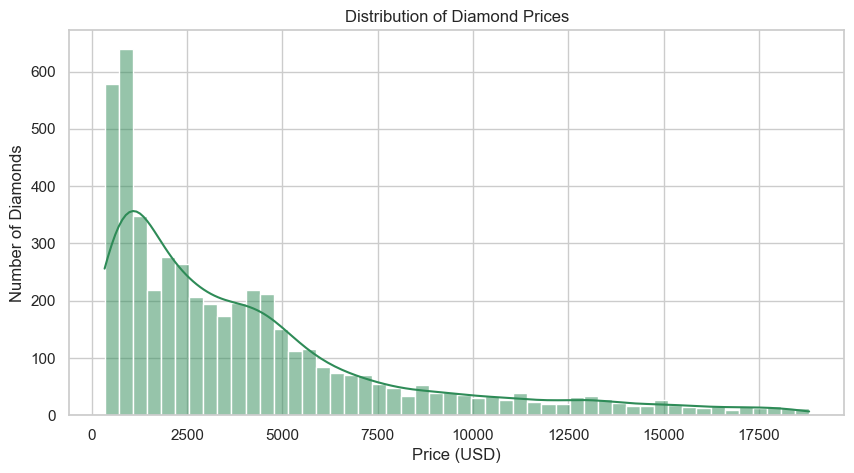

In [8]:
# plot the distribution of diamond prices with a smooth density curve
plt.figure(figsize=(10, 5))
sns.histplot(df['price_usd'], bins=50, color='seagreen', kde=True)
plt.title('Distribution of Diamond Prices')
plt.xlabel('Price (USD)')
plt.ylabel('Number of Diamonds')
plt.show()

Most diamonds sit on the lower end of the price spectrum, while a long right tail stretches into luxury stones above $10,000. This heavy right skew shows that everyday jewelry dominates market volume.

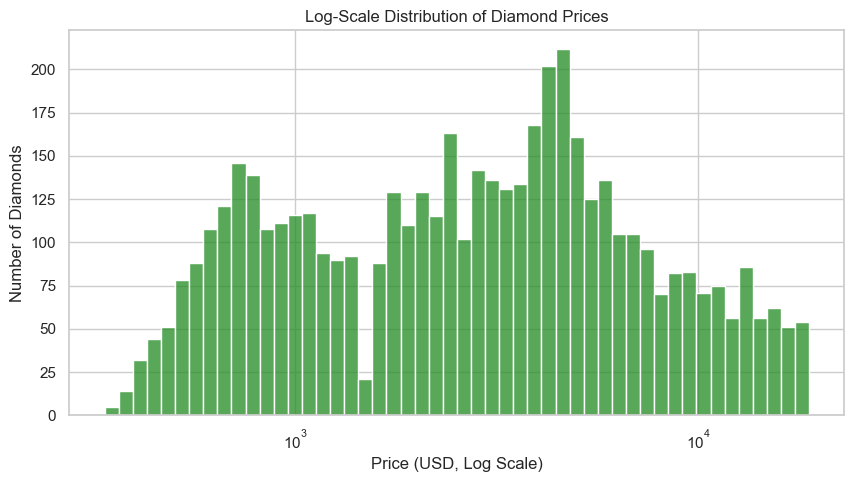

In [9]:
# plot price on a log scale to reveal hidden tiers
plt.figure(figsize=(10, 5))
sns.histplot(df['price_usd'], bins=50, log_scale=True, color='forestgreen')
plt.title('Log-Scale Distribution of Diamond Prices')
plt.xlabel('Price (USD, Log Scale)')
plt.ylabel('Number of Diamonds')
plt.show()

Viewing price on a logarithmic scale uncovers two clear humps—an affordable everyday tier around $700–$1,000 and a larger mid-to-high market tier around $3,000–$5,000.

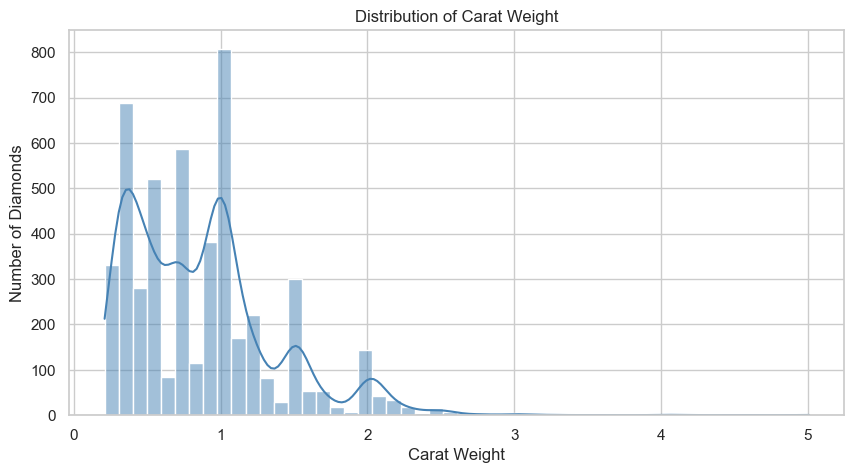

In [10]:
# plot the overall distribution of carat weight
plt.figure(figsize=(10, 5))
sns.histplot(df['carat'], bins=50, color='steelblue', kde=True)
plt.title('Distribution of Carat Weight')
plt.xlabel('Carat Weight')
plt.ylabel('Number of Diamonds')
plt.show()

Just like price, carat weight is heavily right-skewed. Small stones under 1 carat make up the majority of the market, while stones above 2 carats are rare.

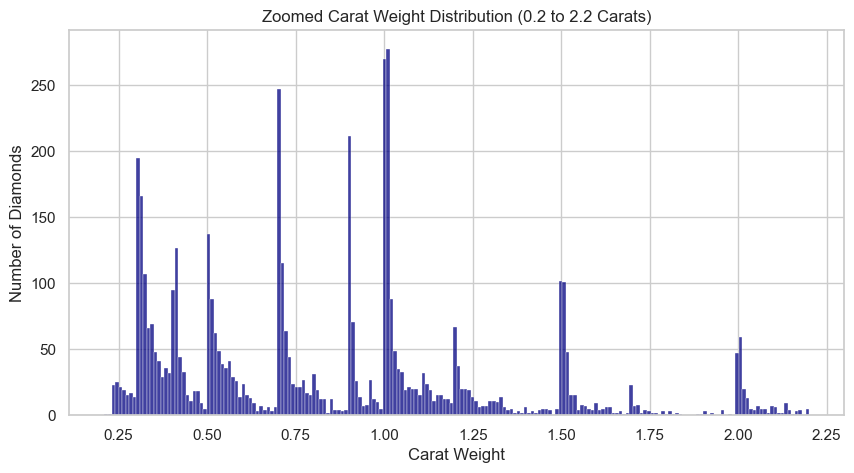

In [11]:
# zoom into carats between 0.2 and 2.2 with fine bins
carat_zoom = df[(df['carat'] >= 0.2) & (df['carat'] <= 2.2)]
plt.figure(figsize=(10, 5))
sns.histplot(carat_zoom['carat'], bins=200, color='navy')
plt.title('Zoomed Carat Weight Distribution (0.2 to 2.2 Carats)')
plt.xlabel('Carat Weight')
plt.ylabel('Number of Diamonds')
plt.show()

Zooming in exposes sharp spikes right at psychological "magic numbers" like 0.3, 0.5, 0.7, 1.0, 1.5, and 2.0 carats. Cutters deliberately preserve weight to cross these profitable buyer thresholds.

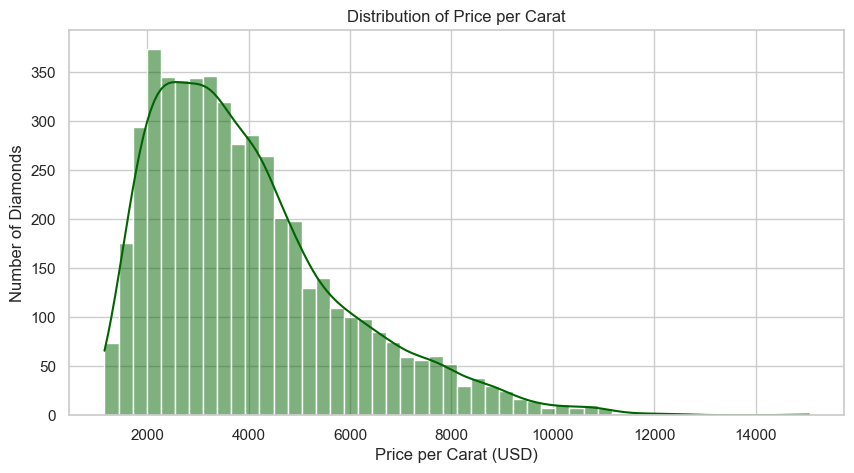

In [12]:
# plot price per carat to normalize for stone weight
plt.figure(figsize=(10, 5))
sns.histplot(df['price_per_carat'], bins=50, color='darkgreen', kde=True)
plt.title('Distribution of Price per Carat')
plt.xlabel('Price per Carat (USD)')
plt.ylabel('Number of Diamonds')
plt.show()

Price per carat levels the playing field by removing raw weight. Even on a per-carat basis, the market is right-skewed, showing that rare combinations of size and quality command steep premiums.

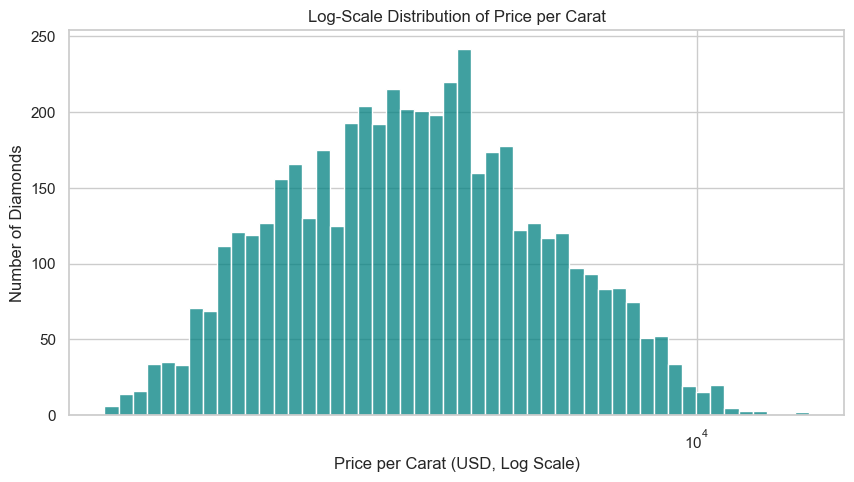

In [13]:
# plot price per carat on a log scale
plt.figure(figsize=(10, 5))
sns.histplot(df['price_per_carat'], bins=50, log_scale=True, color='teal')
plt.title('Log-Scale Distribution of Price per Carat')
plt.xlabel('Price per Carat (USD, Log Scale)')
plt.ylabel('Number of Diamonds')
plt.show()

On a log scale, price per carat looks much closer to a symmetric bell curve centered around $3,500–$4,500 per carat, making it easier to spot unusually cheap or expensive stones.

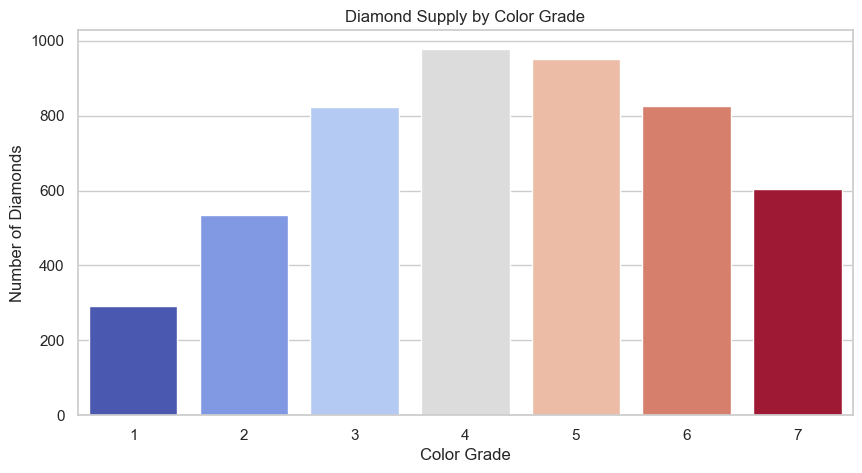

In [14]:
# count how many diamonds belong to each color grade
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='color_grade', hue='color_grade', order=color_order, palette='coolwarm', legend=False)
plt.title('Diamond Supply by Color Grade')
plt.xlabel('Color Grade')
plt.ylabel('Number of Diamonds')
plt.show()

Middle color grades make up the bulk of inventory, while the very extreme ends of the color scale appear less frequently.

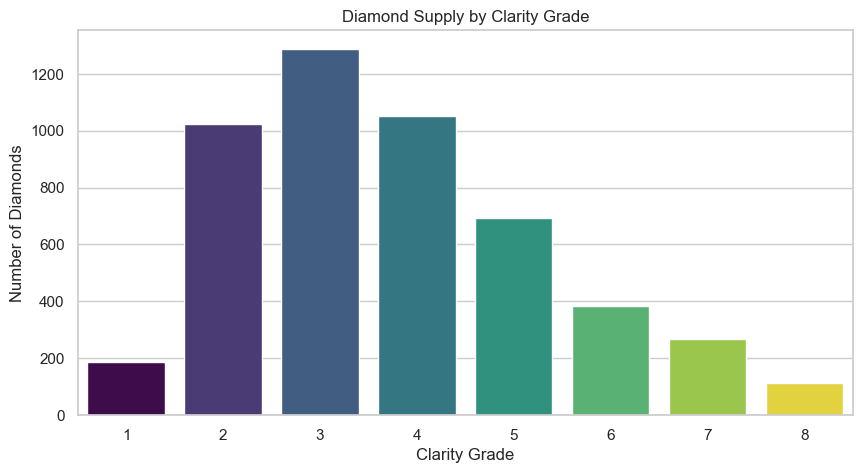

In [15]:
# count how many diamonds belong to each clarity grade
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='clarity_grade', hue='clarity_grade', order=clarity_order, palette='viridis', legend=False)
plt.title('Diamond Supply by Clarity Grade')
plt.xlabel('Clarity Grade')
plt.ylabel('Number of Diamonds')
plt.show()

Mid-range clarity grades dominate the dataset, whereas completely flawless stones and heavily included stones are much rarer in retail supply.

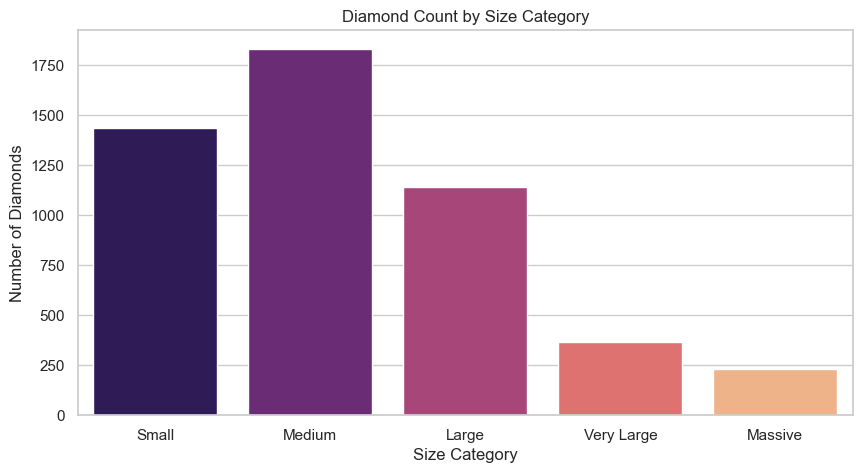

In [16]:
# count diamonds in each size bucket
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='carat_bin', hue='carat_bin', palette='magma', legend=False)
plt.title('Diamond Count by Size Category')
plt.xlabel('Size Category')
plt.ylabel('Number of Diamonds')
plt.show()

Grouping carats into human-friendly size buckets confirms that Small and Medium diamonds (up to 1.0 carat) account for the vast majority of stones, while Massive stones (>2.0 carats) are a tiny niche.

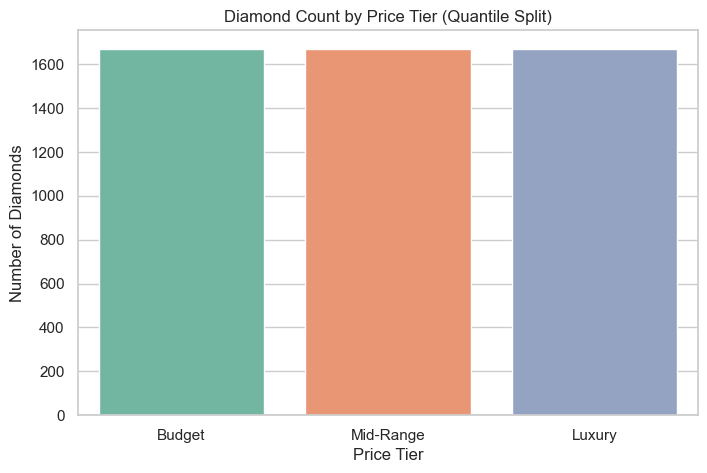

In [17]:
# count diamonds across our three equal-sized price tiers
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='price_tier', hue='price_tier', palette='Set2', legend=False)
plt.title('Diamond Count by Price Tier (Quantile Split)')
plt.xlabel('Price Tier')
plt.ylabel('Number of Diamonds')
plt.show()

Splitting the market into three equal quantile tiers (Budget, Mid-Range, and Luxury) gives us balanced reference groups that will help us compare multi-dimensional patterns later.

### Chapter 2: How Weight and Physical Size Drive Price

Now that we know what the market looks like, we examine the strongest force behind diamond pricing: size.

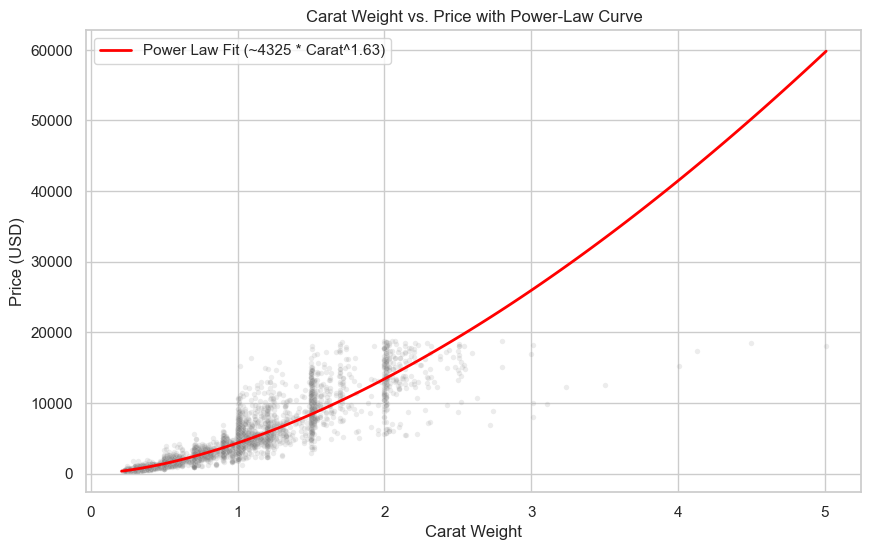

In [18]:
# scatter plot of carat vs price with a power-law reference curve
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='carat', y='price_usd', alpha=0.15, color='gray', s=15)
x_vals = np.linspace(df['carat'].min(), df['carat'].max(), 100)
y_vals = 4325 * (x_vals ** 1.63)
plt.plot(x_vals, y_vals, color='red', linewidth=2, label='Power Law Fit (~4325 * Carat^1.63)')
plt.title('Carat Weight vs. Price with Power-Law Curve')
plt.xlabel('Carat Weight')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()

Price rises faster than weight—it curves upward exponentially. Doubling a diamond's carat weight more than triples its expected price because large rough crystals are exponentially rarer in nature.

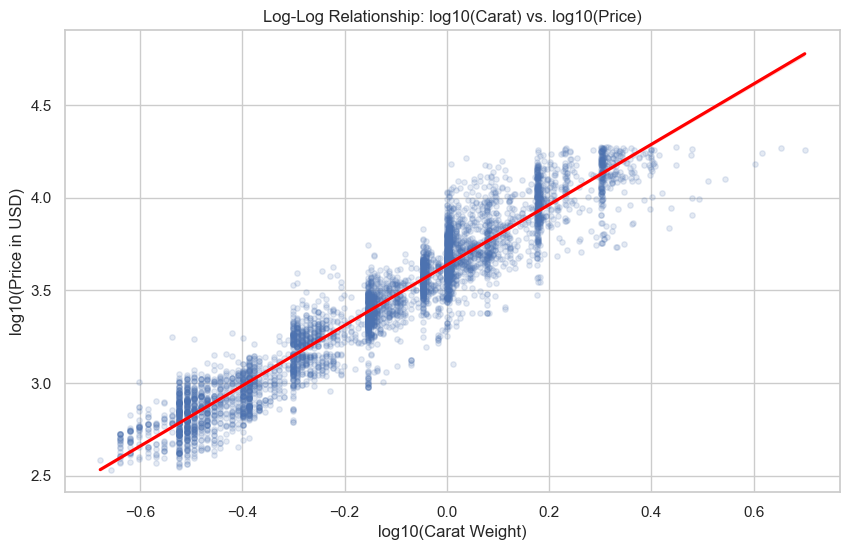

In [19]:
# transform both carat and price with log10 to check if the power law is linear
log_carat = np.log10(df['carat'])
log_price = np.log10(df['price_usd'])
plt.figure(figsize=(10, 6))
sns.regplot(x=log_carat, y=log_price, scatter_kws={'alpha': 0.15, 's': 15}, line_kws={'color': 'red'})
plt.title('Log-Log Relationship: log10(Carat) vs. log10(Price)')
plt.xlabel('log10(Carat Weight)')
plt.ylabel('log10(Price in USD)')
plt.show()

Taking the log of both axes turns the curve into a tight straight line, confirming that diamond pricing follows a clean power-law relationship with carat weight.

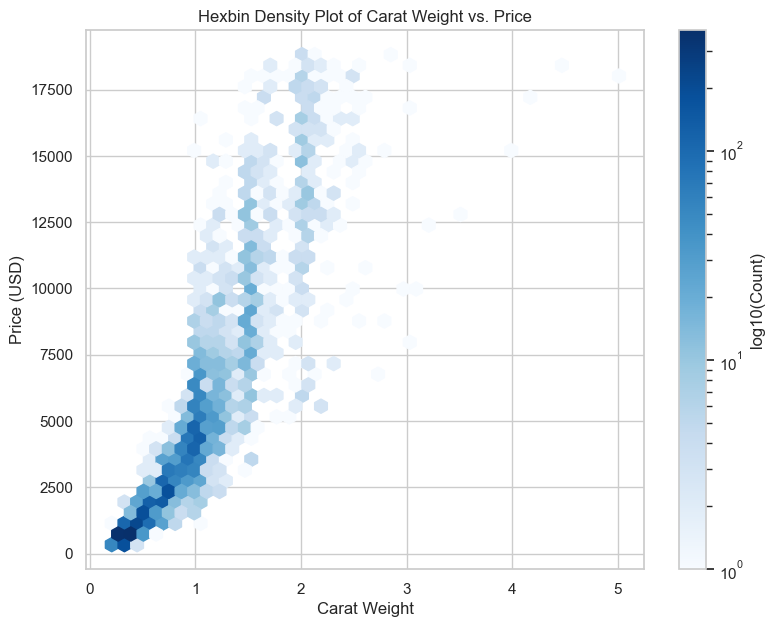

In [20]:
# use hexbin to see where the densest concentration of sales sits
plt.figure(figsize=(9, 7))
plt.hexbin(df['carat'], df['price_usd'], gridsize=40, cmap='Blues', bins='log')
plt.colorbar(label='log10(Count)')
plt.title('Hexbin Density Plot of Carat Weight vs. Price')
plt.xlabel('Carat Weight')
plt.ylabel('Price (USD)')
plt.show()

The darkest hexagons reveal where most diamonds actually cluster: between 0.3 and 1.1 carats, priced under $6,000. Above 1.5 carats, the spread widens dramatically as quality differences amplify price.

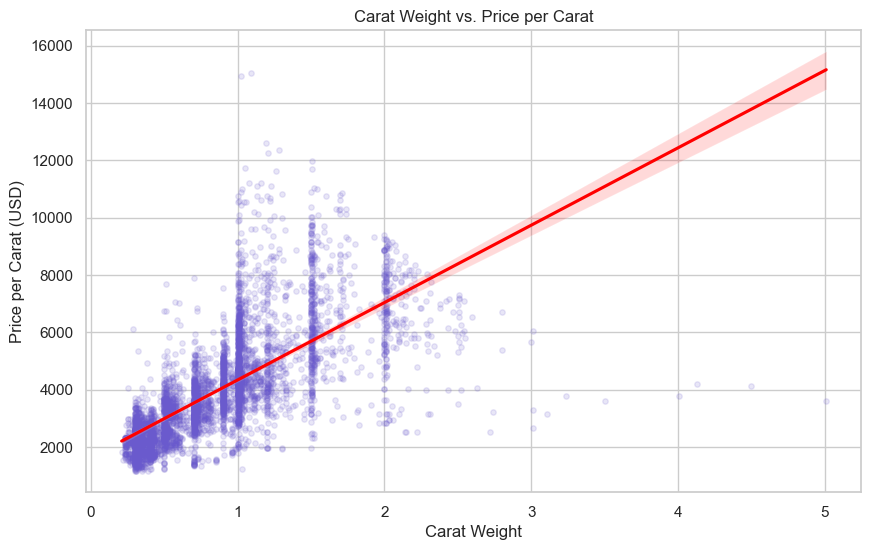

In [21]:
# plot carat against price per carat to show the size premium
plt.figure(figsize=(10, 6))
sns.regplot(data=df, x='carat', y='price_per_carat', scatter_kws={'alpha': 0.15, 's': 15, 'color': 'slateblue'}, line_kws={'color': 'red'})
plt.title('Carat Weight vs. Price per Carat')
plt.xlabel('Carat Weight')
plt.ylabel('Price per Carat (USD)')
plt.show()

Even after dividing price by carat weight, the upward slope proves that bigger stones cost significantly more *per carat* than smaller ones.

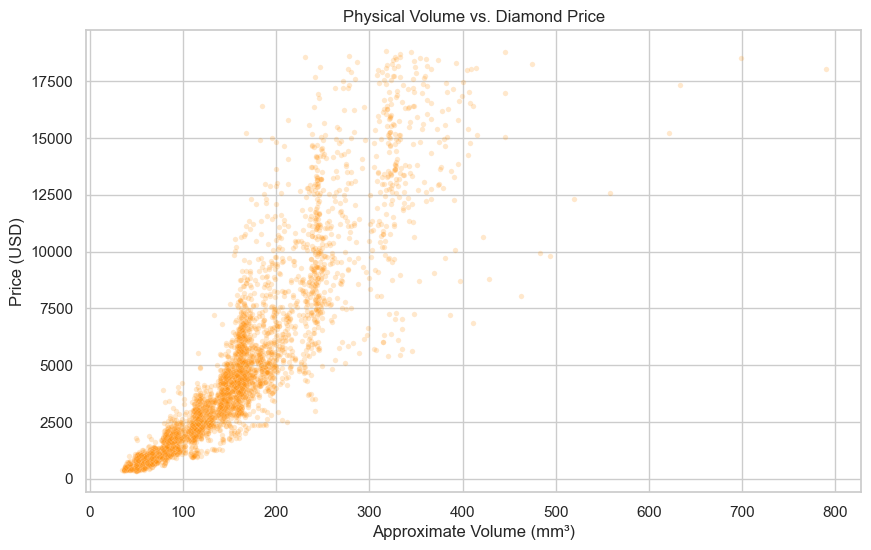

In [22]:
# compare physical volume (L * W * H) against price
plt.figure(figsize=(10, 6))
sns.scatterplot(data=plot_df, x='volume', y='price_usd', alpha=0.2, color='darkorange', s=15)
plt.title('Physical Volume vs. Diamond Price')
plt.xlabel('Approximate Volume (mm³)')
plt.ylabel('Price (USD)')
plt.show()

Physical volume tracks price almost identically to carat weight, showing that buyers are paying for the same underlying physical size factor.

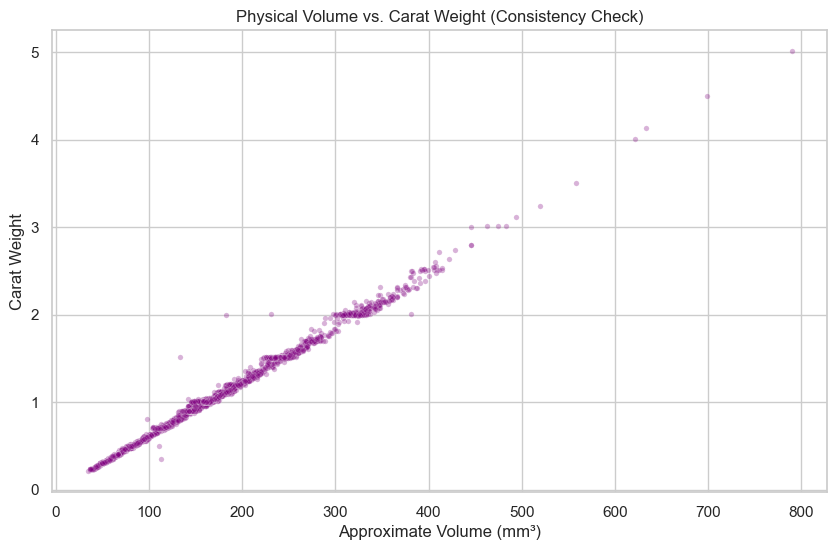

In [23]:
# check how tightly physical volume maps to carat weight
plt.figure(figsize=(10, 6))
sns.scatterplot(data=plot_df, x='volume', y='carat', alpha=0.3, color='purple', s=15)
plt.title('Physical Volume vs. Carat Weight (Consistency Check)')
plt.xlabel('Approximate Volume (mm³)')
plt.ylabel('Carat Weight')
plt.show()

Volume and carat sit on a razor-sharp diagonal line because diamonds have a constant mineral density. Any dots far off this line immediately expose measurement glitches or unusual cuts.

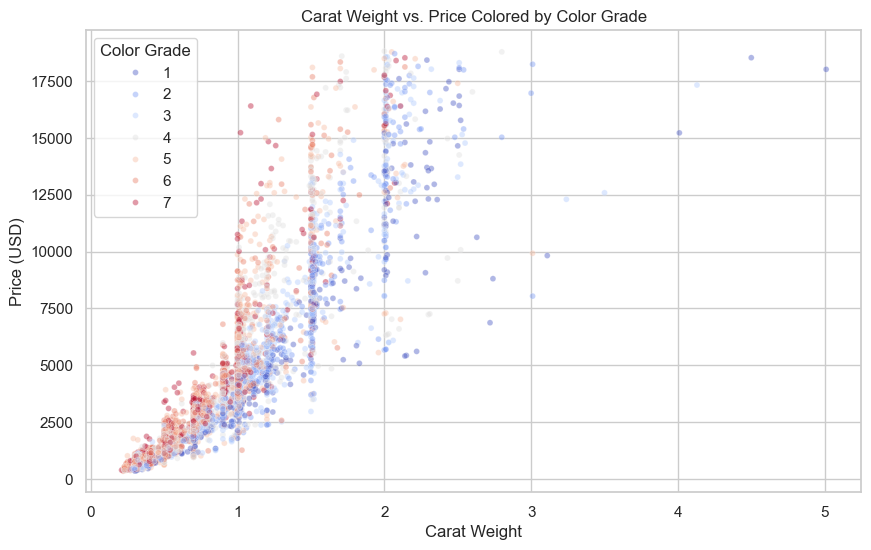

In [24]:
# layer color grade onto the carat vs price curve
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='carat', y='price_usd', hue='color_grade', hue_order=color_order, palette='coolwarm', alpha=0.4, s=18)
plt.title('Carat Weight vs. Price Colored by Color Grade')
plt.xlabel('Carat Weight')
plt.ylabel('Price (USD)')
plt.legend(title='Color Grade')
plt.show()

At any fixed carat weight (for example, right at 1.0 carat), the vertical spread in price is partly explained by color grade—better color grades consistently sit higher on the curve.

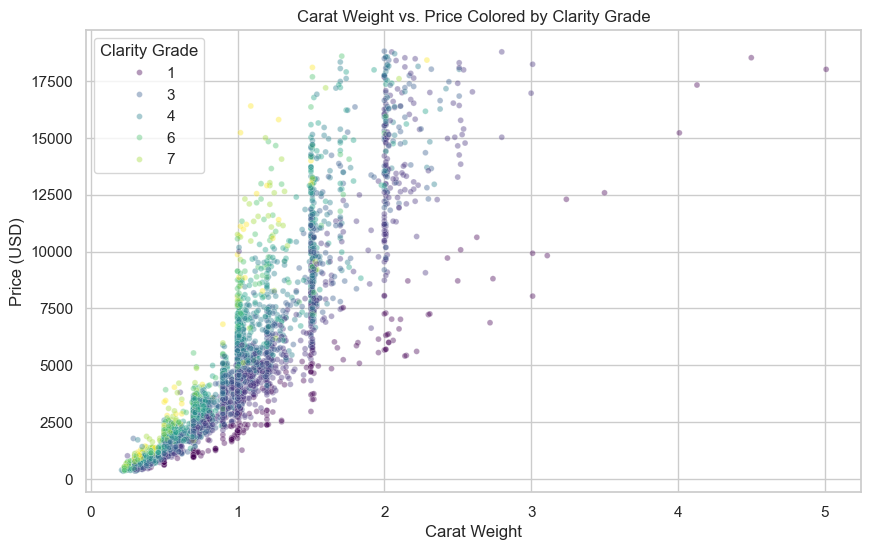

In [25]:
# layer clarity grade onto the carat vs price curve
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='carat', y='price_usd', hue='clarity_grade', hue_order=clarity_order, palette='viridis', alpha=0.4, s=18)
plt.title('Carat Weight vs. Price Colored by Clarity Grade')
plt.xlabel('Carat Weight')
plt.ylabel('Price (USD)')
plt.legend(title='Clarity Grade')
plt.show()

Clarity creates even stronger vertical banding at the same carat weight, separating lower-priced included stones from high-priced clean stones of identical size.

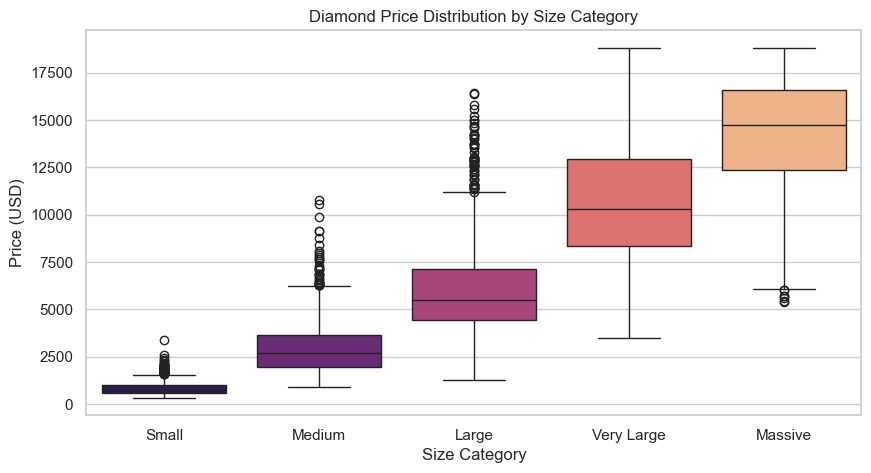

In [26]:
# compare total price across our five size categories
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='carat_bin', y='price_usd', hue='carat_bin', palette='magma', legend=False)
plt.title('Diamond Price Distribution by Size Category')
plt.xlabel('Size Category')
plt.ylabel('Price (USD)')
plt.show()

Each step up in size category triggers a steep jump in both median price and price range, confirming that carat tier is the primary market divider.

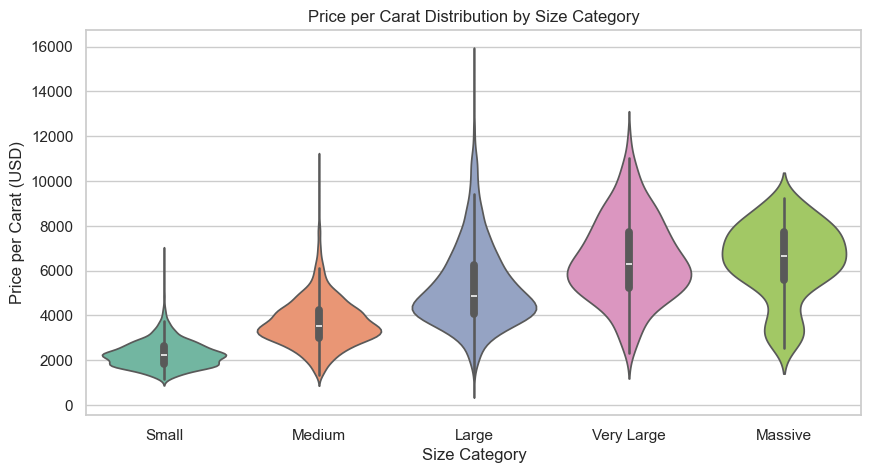

In [27]:
# compare price per carat across size categories using violin plots
plt.figure(figsize=(10, 5))
sns.violinplot(data=df, x='carat_bin', y='price_per_carat', hue='carat_bin', palette='Set2', legend=False)
plt.title('Price per Carat Distribution by Size Category')
plt.xlabel('Size Category')
plt.ylabel('Price per Carat (USD)')
plt.show()

The violin shapes widen dramatically once stones cross 1.0 carat, meaning quality grades matter much more in dollar terms for large diamonds than for small ones.

### Chapter 3: Cut Geometry, Proportions, and Sharpness Standards

Beyond weight, how are diamonds physically shaped? Here we inspect millimeter dimensions, depth and table standards, roundness, and physical sharpness.

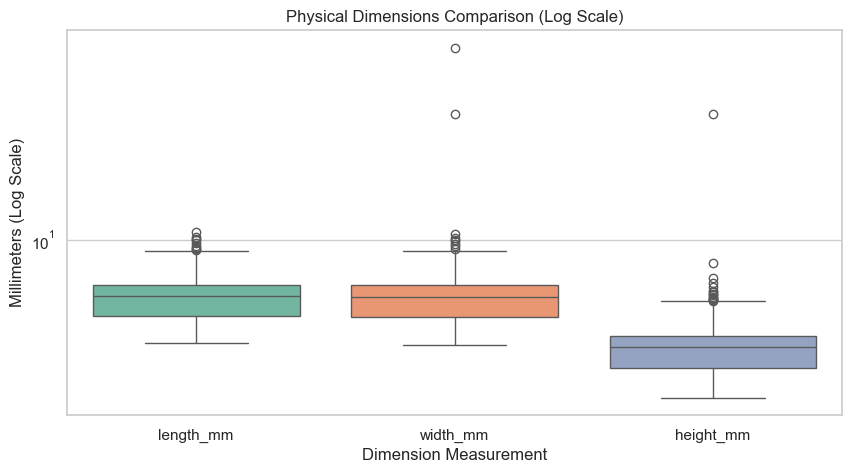

In [28]:
# compare length, width, and height side by side on a log scale
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[['length_mm', 'width_mm', 'height_mm']], palette='Set2')
plt.yscale('log')
plt.title('Physical Dimensions Comparison (Log Scale)')
plt.xlabel('Dimension Measurement')
plt.ylabel('Millimeters (Log Scale)')
plt.show()

Length and width have nearly identical distributions (around 5–7 mm), while height is consistently smaller (around 3–4 mm) because diamonds are cut wider than they are tall. The log scale also highlights a few extreme outliers.

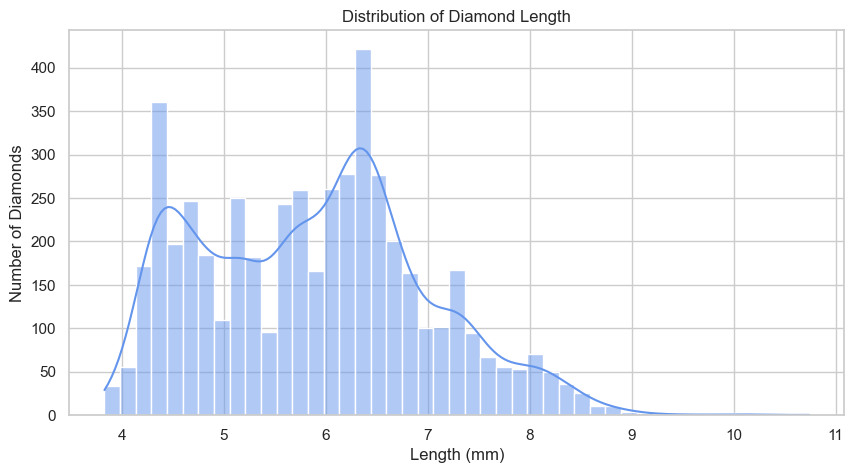

In [29]:
# plot the distribution of diamond length
plt.figure(figsize=(10, 5))
sns.histplot(plot_df['length_mm'], bins=45, color='cornflowerblue', kde=True)
plt.title('Distribution of Diamond Length')
plt.xlabel('Length (mm)')
plt.ylabel('Number of Diamonds')
plt.show()

Diamond length shows multiple peaks corresponding to the popular carat milestones (such as ~4.3 mm for 0.3 ct and ~6.4 mm for 1.0 ct).

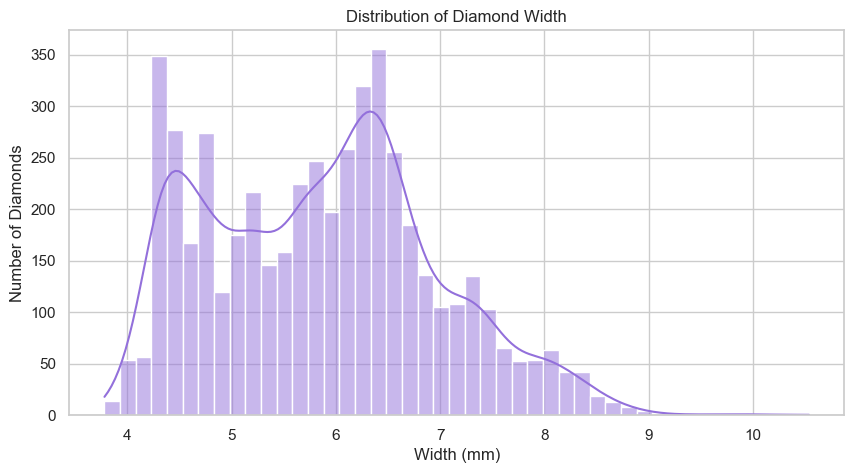

In [30]:
# plot the distribution of diamond width
plt.figure(figsize=(10, 5))
sns.histplot(plot_df['width_mm'], bins=45, color='mediumpurple', kde=True)
plt.title('Distribution of Diamond Width')
plt.xlabel('Width (mm)')
plt.ylabel('Number of Diamonds')
plt.show()

Width mirrors length almost peak for peak, reinforcing that the vast majority of stones in this dataset are symmetrical round brilliant cuts.

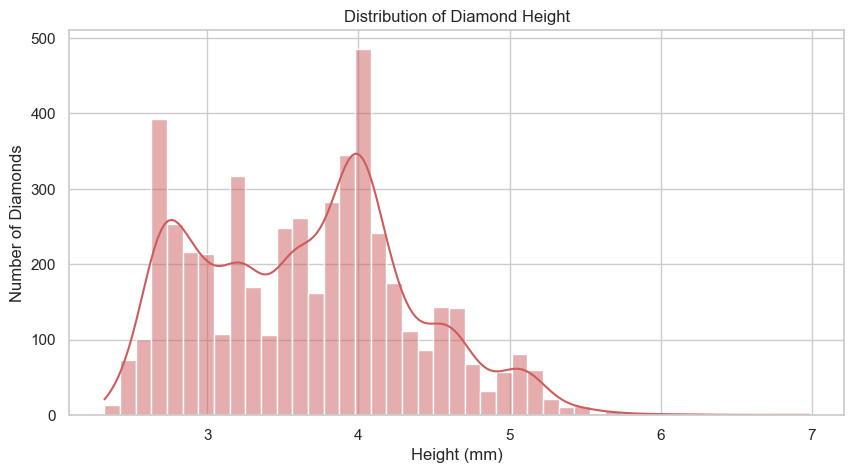

In [31]:
# plot the distribution of diamond height
plt.figure(figsize=(10, 5))
sns.histplot(plot_df['height_mm'], bins=45, color='indianred', kde=True)
plt.title('Distribution of Diamond Height')
plt.xlabel('Height (mm)')
plt.ylabel('Number of Diamonds')
plt.show()

Height follows the same multi-modal pattern as length and width, just scaled down by roughly 60–62% to match standard diamond proportions.

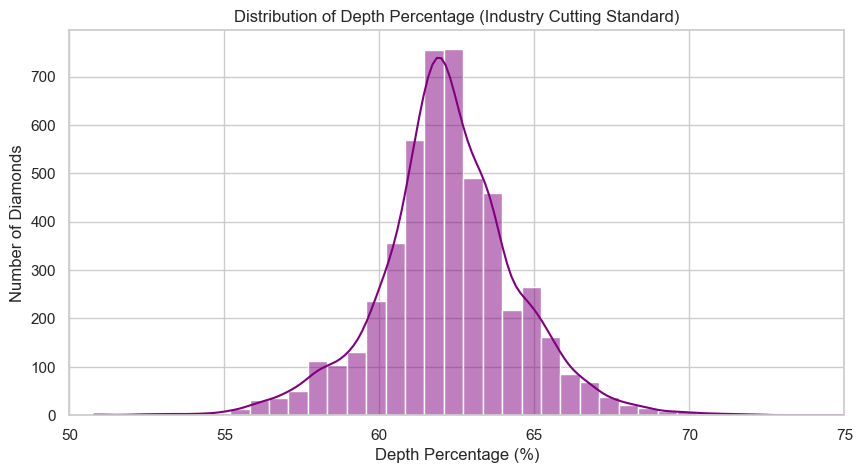

In [32]:
# plot depth percentage zoomed into the realistic 50 to 75 range
plt.figure(figsize=(10, 5))
sns.histplot(df['depth_pct'].dropna(), bins=45, color='purple', kde=True)
plt.xlim(50, 75)
plt.title('Distribution of Depth Percentage (Industry Cutting Standard)')
plt.xlabel('Depth Percentage (%)')
plt.ylabel('Number of Diamonds')
plt.show()

Unlike carat or price, depth percentage is tightly clustered in a narrow bell curve around 61–63%. Cutters aim for this optical sweet spot so light reflects back out the top instead of leaking through the bottom.

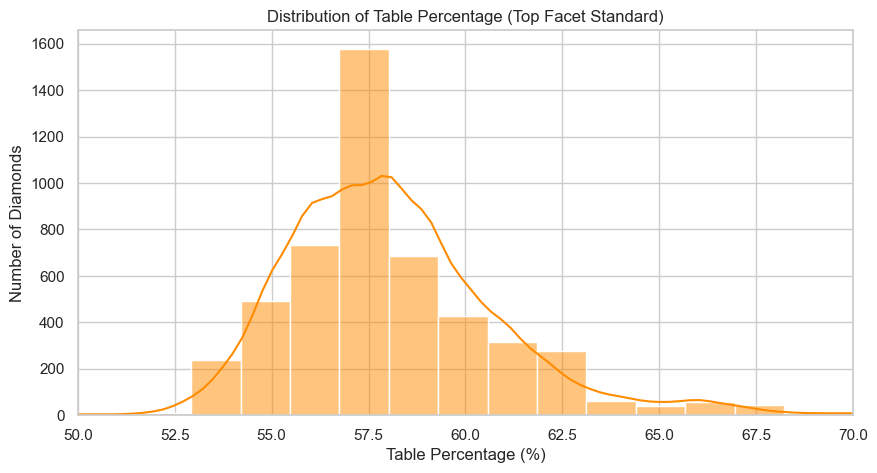

In [33]:
# plot table percentage zoomed into the realistic 50 to 70 range
plt.figure(figsize=(10, 5))
sns.histplot(df['table_pct'].dropna(), bins=40, color='darkorange', kde=True)
plt.xlim(50, 70)
plt.title('Distribution of Table Percentage (Top Facet Standard)')
plt.xlabel('Table Percentage (%)')
plt.ylabel('Number of Diamonds')
plt.show()

Table percentage is also tightly controlled between 55% and 60%, with noticeable spikes at whole integers because jewelers often round table measurements to the nearest percent.

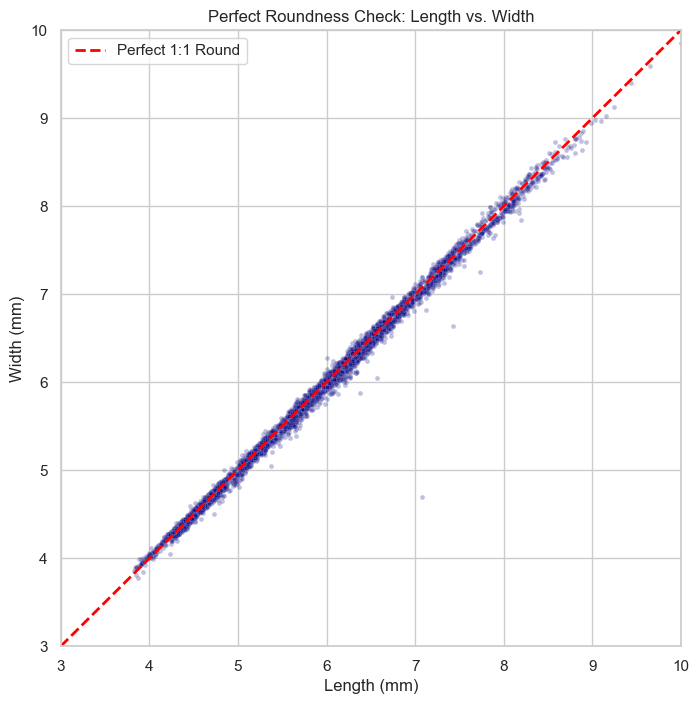

In [34]:
# plot length against width with a 1:1 line for perfect roundness
plt.figure(figsize=(8, 8))
sns.scatterplot(data=plot_df, x='length_mm', y='width_mm', alpha=0.25, color='navy', s=12)
plt.plot([3, 10], [3, 10], color='red', linestyle='--', linewidth=2, label='Perfect 1:1 Round')
plt.xlim(3, 10)
plt.ylim(3, 10)
plt.title('Perfect Roundness Check: Length vs. Width')
plt.xlabel('Length (mm)')
plt.ylabel('Width (mm)')
plt.legend()
plt.show()

Nearly every diamond lies directly on the red 1:1 diagonal line, confirming that almost the entire catalog consists of round stones with only a handful of slightly elongated or oval outliers.

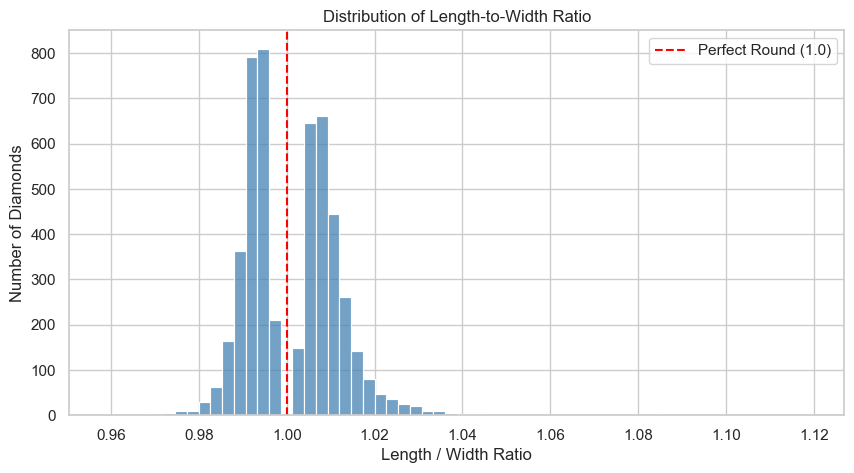

In [35]:
# plot the length-to-width ratio zoomed around 1.0
lw_zoom = df[(df['l_w_ratio'] >= 0.9) & (df['l_w_ratio'] <= 1.3)]
plt.figure(figsize=(10, 5))
sns.histplot(lw_zoom['l_w_ratio'], bins=60, color='steelblue')
plt.axvline(1.0, color='red', linestyle='--', label='Perfect Round (1.0)')
plt.title('Distribution of Length-to-Width Ratio')
plt.xlabel('Length / Width Ratio')
plt.ylabel('Number of Diamonds')
plt.legend()
plt.show()

The overwhelming spike right at 1.0 confirms high symmetry across the dataset, with very few stones exceeding a 1.05 elongation ratio.

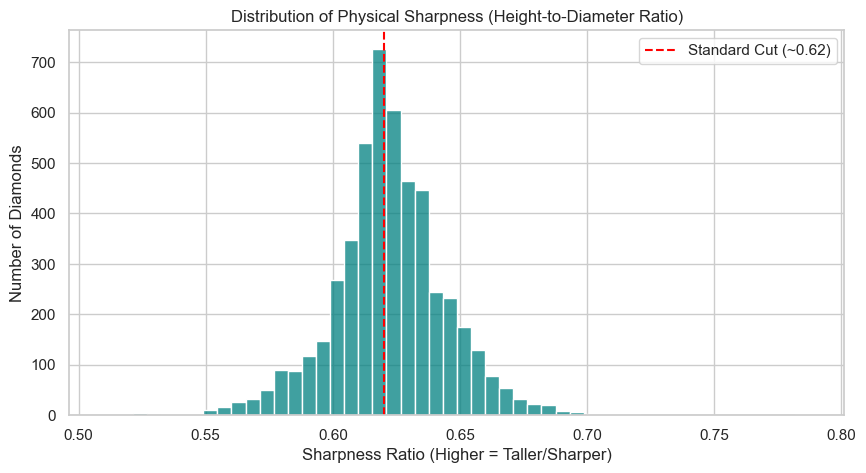

In [36]:
# plot physical sharpness ratio with a reference line at the standard 0.62 cut
plt.figure(figsize=(10, 5))
sns.histplot(plot_df['sharpness_ratio'], bins=50, color='teal')
plt.axvline(0.62, color='red', linestyle='--', label='Standard Cut (~0.62)')
plt.title('Distribution of Physical Sharpness (Height-to-Diameter Ratio)')
plt.xlabel('Sharpness Ratio (Higher = Taller/Sharper)')
plt.ylabel('Number of Diamonds')
plt.legend()
plt.show()

Physically sharp or overly tall diamonds (ratio above 0.70) are rare. Cutters avoid steep proportions because tall stones trap or leak light and appear smaller face-up than their carat weight suggests.

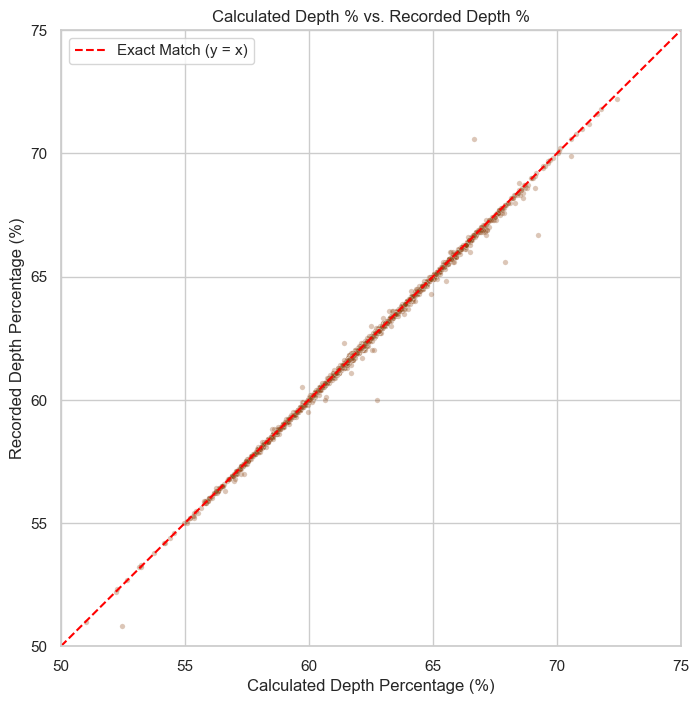

In [37]:
# compare mathematically calculated depth against recorded depth_pct
plt.figure(figsize=(8, 8))
sns.scatterplot(data=plot_df, x='calc_depth_pct', y='depth_pct', alpha=0.3, color='saddlebrown', s=15)
plt.plot([50, 75], [50, 75], color='red', linestyle='--', label='Exact Match (y = x)')
plt.xlim(50, 75)
plt.ylim(50, 75)
plt.title('Calculated Depth % vs. Recorded Depth %')
plt.xlabel('Calculated Depth Percentage (%)')
plt.ylabel('Recorded Depth Percentage (%)')
plt.legend()
plt.show()

Almost all points hug the exact `y = x` line, verifying that our depth recovery formula matches the dataset's recording convention and that only a tiny number of rows have measurement discrepancies.

### Chapter 4: Cutting Sweet Spots and the Quality Paradoxes

Do cutting proportions directly boost price? And why do lower color and clarity grades sometimes look *more* expensive on average? Let's uncover the paradoxes.

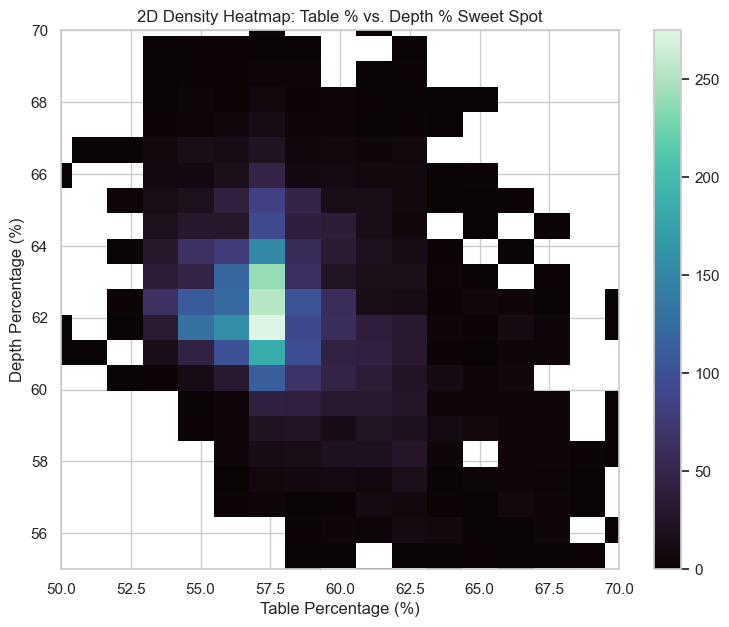

In [38]:
# 2d density histogram showing the table vs depth cutting bullseye
plt.figure(figsize=(9, 7))
sns.histplot(data=plot_df.dropna(subset=['table_pct', 'depth_pct']), x='table_pct', y='depth_pct', bins=40, cmap='mako', cbar=True)
plt.xlim(50, 70)
plt.ylim(55, 70)
plt.title('2D Density Heatmap: Table % vs. Depth % Sweet Spot')
plt.xlabel('Table Percentage (%)')
plt.ylabel('Depth Percentage (%)')
plt.show()

This density map highlights the exact industry bullseye: most stones are cut right around 56–58% table and 61–63% depth.

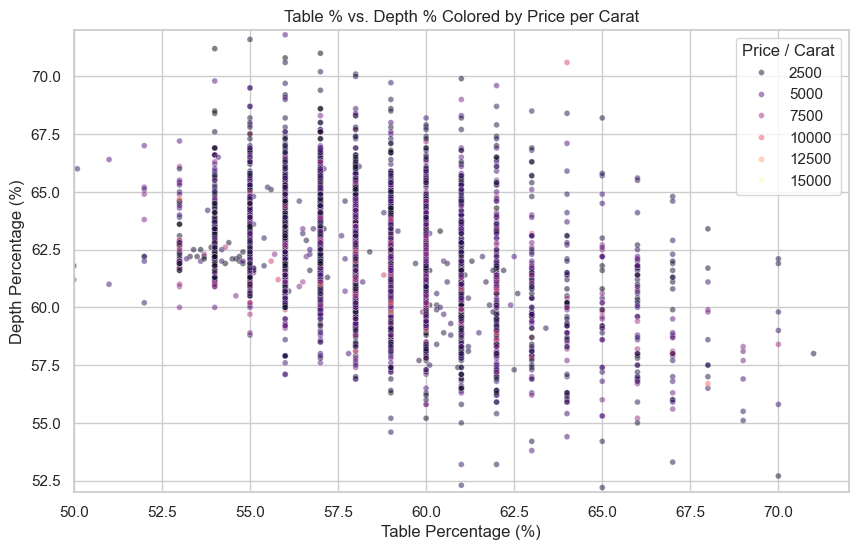

In [39]:
# scatter table vs depth colored by price per carat
plt.figure(figsize=(10, 6))
sns.scatterplot(data=plot_df.dropna(subset=['table_pct', 'depth_pct']), x='table_pct', y='depth_pct', hue='price_per_carat', palette='magma', alpha=0.5, s=18)
plt.xlim(50, 72)
plt.ylim(52, 72)
plt.title('Table % vs. Depth % Colored by Price per Carat')
plt.xlabel('Table Percentage (%)')
plt.ylabel('Depth Percentage (%)')
plt.legend(title='Price / Carat')
plt.show()

High price-per-carat stones appear right inside the cutting sweet spot, while stones drifting far outside standard proportions rarely achieve top per-carat prices.

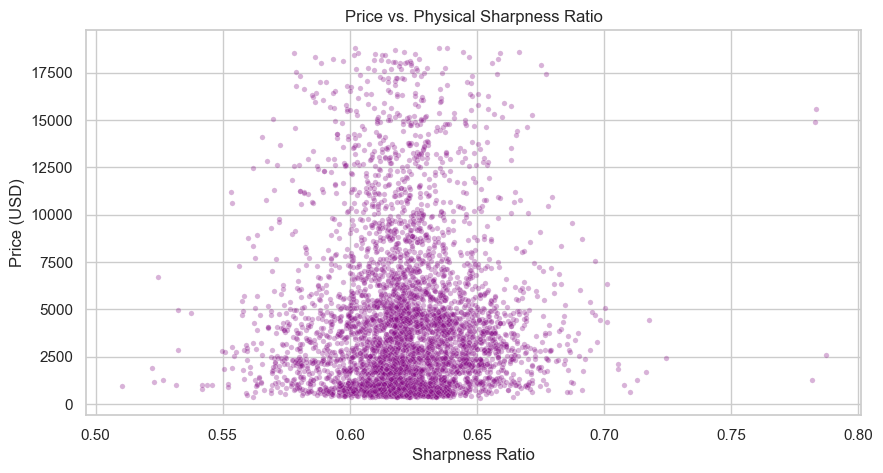

In [40]:
# check if sharper/taller diamonds sell for more
plt.figure(figsize=(10, 5))
sns.scatterplot(data=plot_df, x='sharpness_ratio', y='price_usd', alpha=0.3, color='purple', s=15)
plt.title('Price vs. Physical Sharpness Ratio')
plt.xlabel('Sharpness Ratio')
plt.ylabel('Price (USD)')
plt.show()

There is practically zero positive relationship between physical sharpness and price—expensive diamonds cluster right near the balanced 0.61–0.63 ratio rather than at extreme heights.

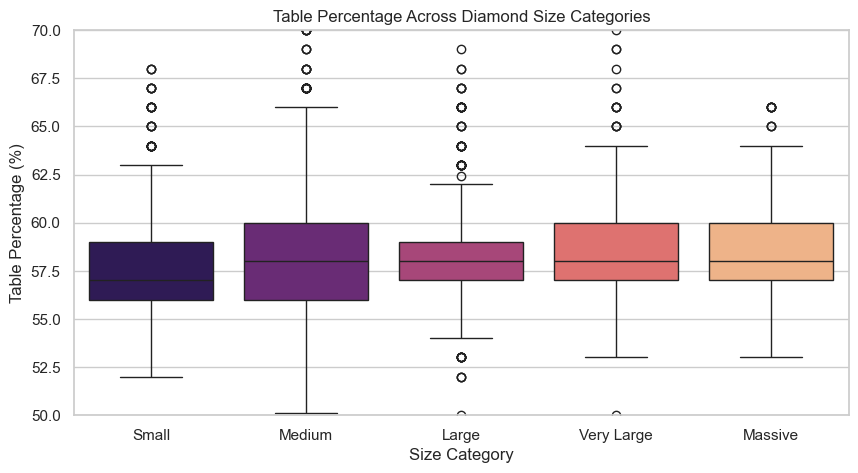

In [41]:
# check whether cutters use different table percentages for larger diamonds
plt.figure(figsize=(10, 5))
sns.boxplot(data=plot_df, x='carat_bin', y='table_pct', hue='carat_bin', palette='magma', legend=False)
plt.ylim(50, 70)
plt.title('Table Percentage Across Diamond Size Categories')
plt.xlabel('Size Category')
plt.ylabel('Table Percentage (%)')
plt.show()

Median table percentage rises slightly for larger diamonds, suggesting cutters occasionally widen the top facet on big rough stones to preserve carat weight.

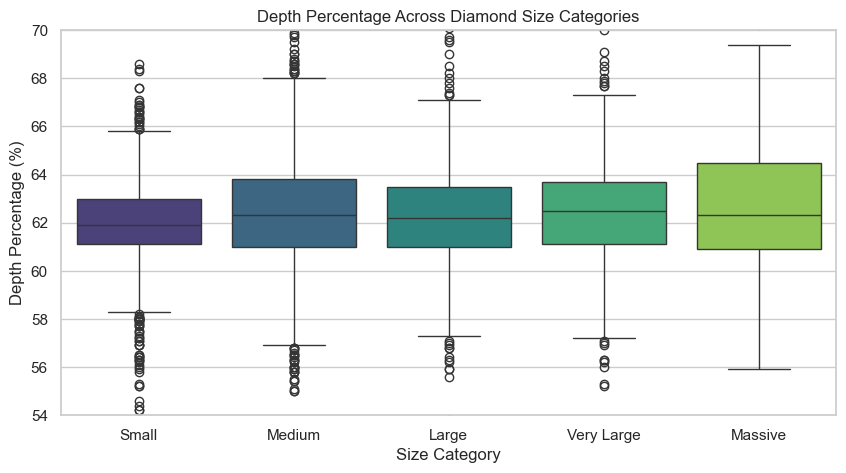

In [42]:
# check whether depth percentage stays consistent across diamond sizes
plt.figure(figsize=(10, 5))
sns.boxplot(data=plot_df, x='carat_bin', y='depth_pct', hue='carat_bin', palette='viridis', legend=False)
plt.ylim(54, 70)
plt.title('Depth Percentage Across Diamond Size Categories')
plt.xlabel('Size Category')
plt.ylabel('Depth Percentage (%)')
plt.show()

Depth percentage stays remarkably steady around 62% across all five size tiers, though massive stones show slightly wider variation.

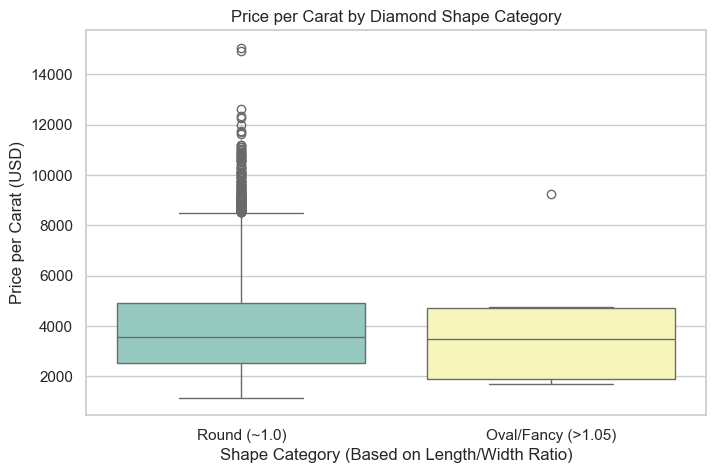

In [43]:
# compare price per carat between round stones and slightly elongated/fancy shapes
plt.figure(figsize=(8, 5))
sns.boxplot(data=df.dropna(subset=['shape_category']), x='shape_category', y='price_per_carat', hue='shape_category', palette='Set3', legend=False)
plt.title('Price per Carat by Diamond Shape Category')
plt.xlabel('Shape Category (Based on Length/Width Ratio)')
plt.ylabel('Price per Carat (USD)')
plt.show()

Comparing standard round stones against elongated or fancy-ratio stones shows whether off-round geometry carries a price discount or premium per carat.

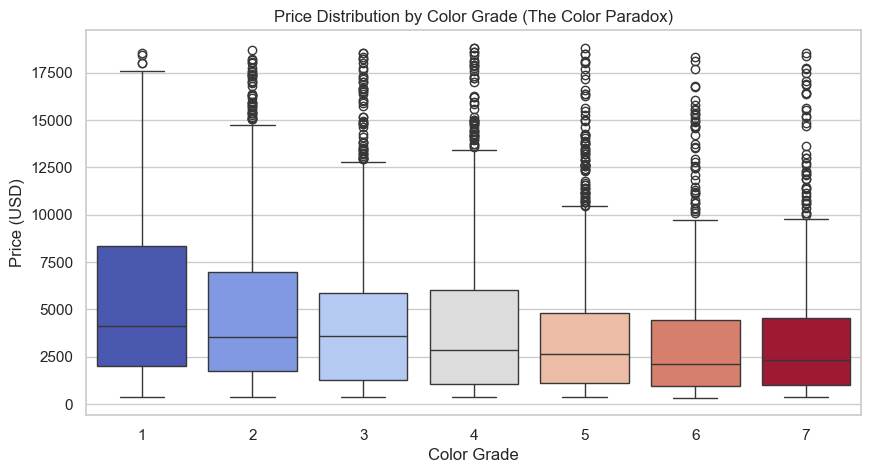

In [44]:
# plot total price by color grade to reveal the color paradox
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='color_grade', y='price_usd', hue='color_grade', order=color_order, palette='coolwarm', legend=False)
plt.title('Price Distribution by Color Grade (The Color Paradox)')
plt.xlabel('Color Grade')
plt.ylabel('Price (USD)')
plt.show()

Counter-intuitively, lower color grades often show higher median prices than top color grades. Looking at raw price alone hides a major confounding variable: carat weight.

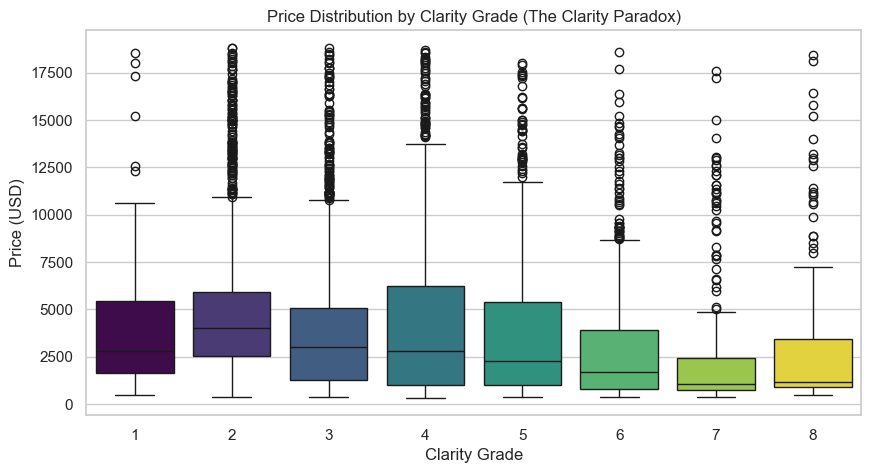

In [45]:
# plot total price by clarity grade to reveal the clarity paradox
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='clarity_grade', y='price_usd', hue='clarity_grade', order=clarity_order, palette='viridis', legend=False)
plt.title('Price Distribution by Clarity Grade (The Clarity Paradox)')
plt.xlabel('Clarity Grade')
plt.ylabel('Price (USD)')
plt.show()

The same paradox appears for clarity: the cleanest grades do not automatically have the highest median total price. Next, we check carat weight to see why.

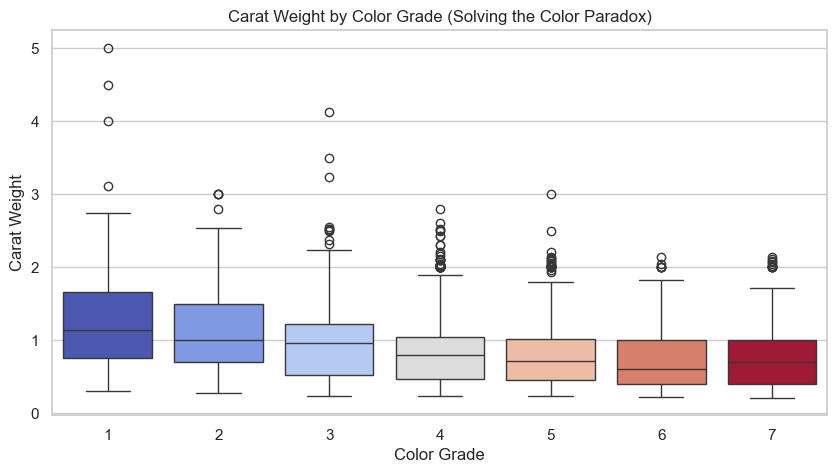

In [46]:
# plot carat weight by color grade to explain the color paradox
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='color_grade', y='carat', hue='color_grade', order=color_order, palette='coolwarm', legend=False)
plt.title('Carat Weight by Color Grade (Solving the Color Paradox)')
plt.xlabel('Color Grade')
plt.ylabel('Carat Weight')
plt.show()

Here is the explanation: lower color grades tend to be heavier stones on average. Buyers frequently trade off color to afford a bigger diamond, and size pushes total price up faster than color pushes it down.

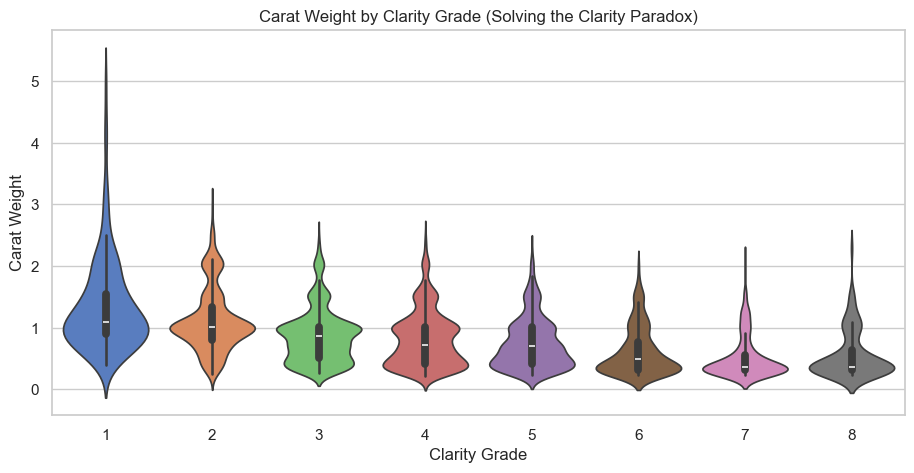

In [47]:
# plot carat weight by clarity grade using violin plots to explain the clarity paradox
plt.figure(figsize=(11, 5))
sns.violinplot(data=df, x='clarity_grade', y='carat', hue='clarity_grade', order=clarity_order, palette='muted', legend=False)
plt.title('Carat Weight by Clarity Grade (Solving the Clarity Paradox)')
plt.xlabel('Clarity Grade')
plt.ylabel('Carat Weight')
plt.show()

Flawless and internally clean crystals are far more common in small sizes than in large ones. Because high-clarity diamonds are typically lighter, their raw total price looks lower than heavier, more included stones.

### Chapter 5: True Value, Multi-Variable Interactions, and Clustering Readiness

Finally, we remove the size bias using price per carat, explore 2D and 3D multi-feature interactions, and inspect correlations to prepare for dimensionality reduction and clustering.

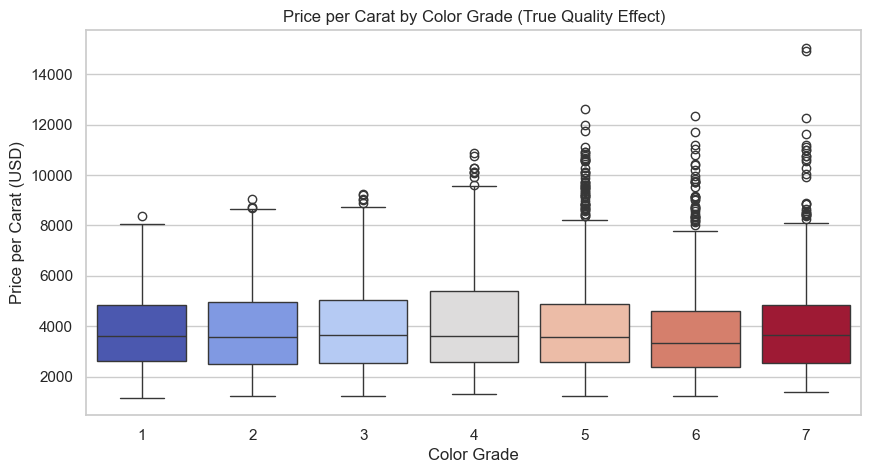

In [48]:
# plot price per carat by color grade to see the true quality premium
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='color_grade', y='price_per_carat', hue='color_grade', order=color_order, palette='coolwarm', legend=False)
plt.title('Price per Carat by Color Grade (True Quality Effect)')
plt.xlabel('Color Grade')
plt.ylabel('Price per Carat (USD)')
plt.show()

Once we normalize by weight, the market behaves much more logically: better color grades command stronger per-carat value without being masked by carat size.

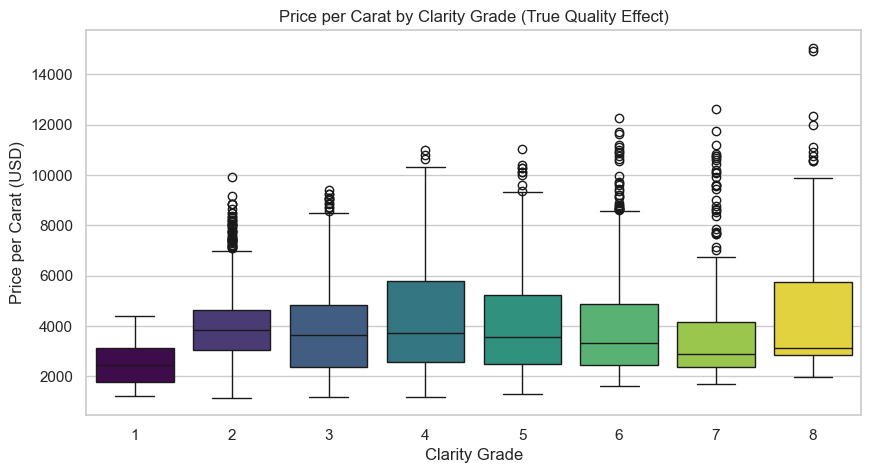

In [49]:
# plot price per carat by clarity grade
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='clarity_grade', y='price_per_carat', hue='clarity_grade', order=clarity_order, palette='viridis', legend=False)
plt.title('Price per Carat by Clarity Grade (True Quality Effect)')
plt.xlabel('Clarity Grade')
plt.ylabel('Price per Carat (USD)')
plt.show()

Price per carat also clarifies the value of clarity, showing clearer upward separation across grades compared to raw total price.

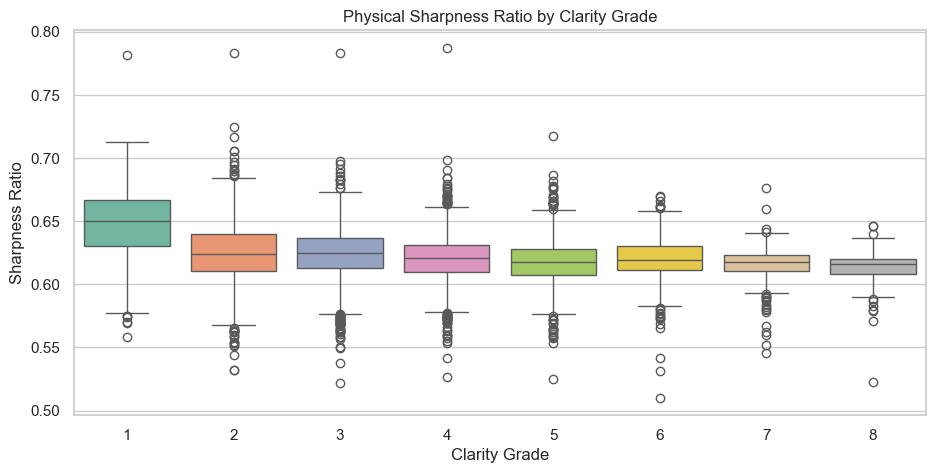

In [50]:
# check if higher clarity diamonds are cut to tighter sharpness standards
plt.figure(figsize=(11, 5))
sns.boxplot(data=plot_df, x='clarity_grade', y='sharpness_ratio', hue='clarity_grade', order=clarity_order, palette='Set2', legend=False)
plt.title('Physical Sharpness Ratio by Clarity Grade')
plt.xlabel('Clarity Grade')
plt.ylabel('Sharpness Ratio')
plt.show()

Higher clarity grades show tighter, more consistent boxes around the ideal 0.62 sharpness ratio, reflecting stricter craftsmanship on cleaner rough stones.

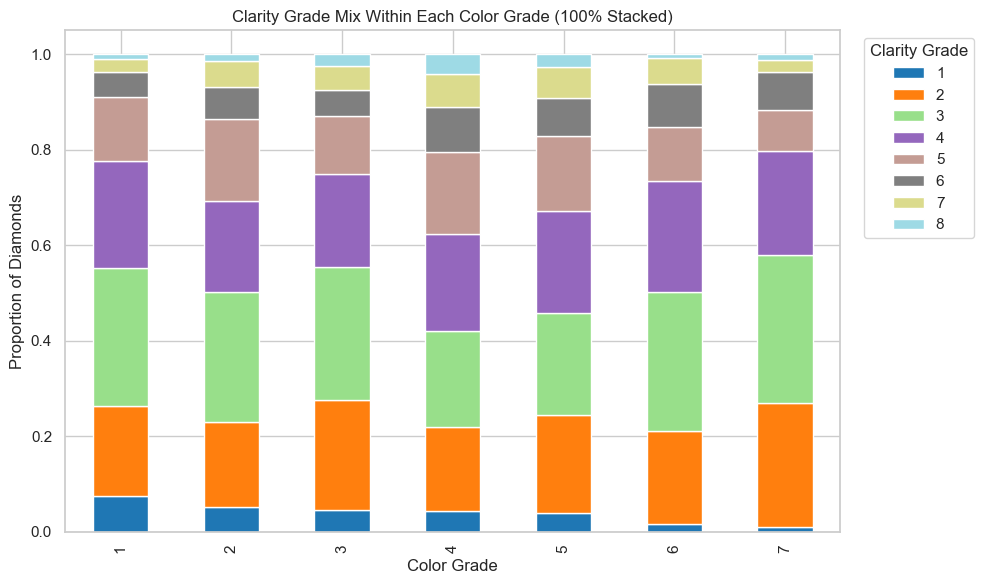

In [51]:
# build a 100% stacked bar chart of clarity mix inside each color grade
crosstab = pd.crosstab(df['color_grade'], df['clarity_grade'], normalize='index')
crosstab.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='tab20')
plt.title('Clarity Grade Mix Within Each Color Grade (100% Stacked)')
plt.xlabel('Color Grade')
plt.ylabel('Proportion of Diamonds')
plt.legend(title='Clarity Grade', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

This stacked breakdown shows that clarity and color are mostly independent, though certain color tiers carry a slightly higher share of top clarity grades.

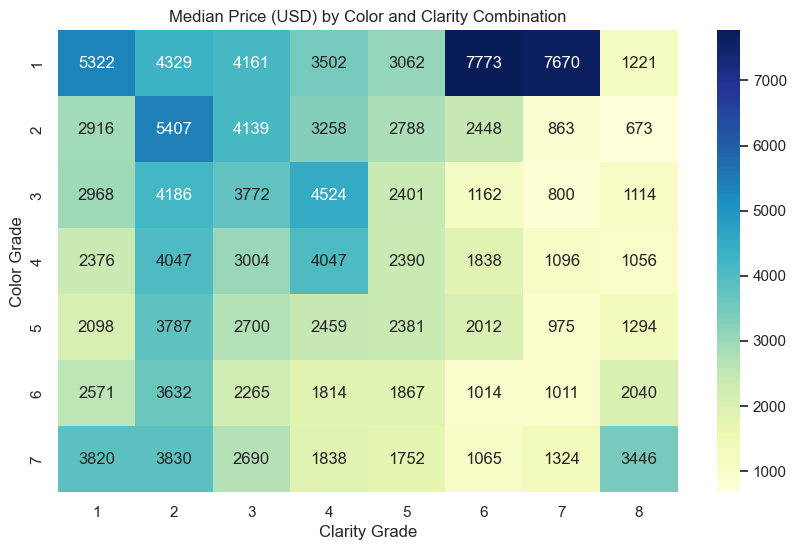

In [52]:
# create a heatmap of median price for every color and clarity pair
pivot_price = df.pivot_table(index='color_grade', columns='clarity_grade', values='price_usd', aggfunc='median')
plt.figure(figsize=(10, 6))
sns.heatmap(pivot_price, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Median Price (USD) by Color and Clarity Combination')
plt.xlabel('Clarity Grade')
plt.ylabel('Color Grade')
plt.show()

The color-by-clarity matrix pinpoints exactly which grade combinations yield the highest median ticket prices across the catalog.

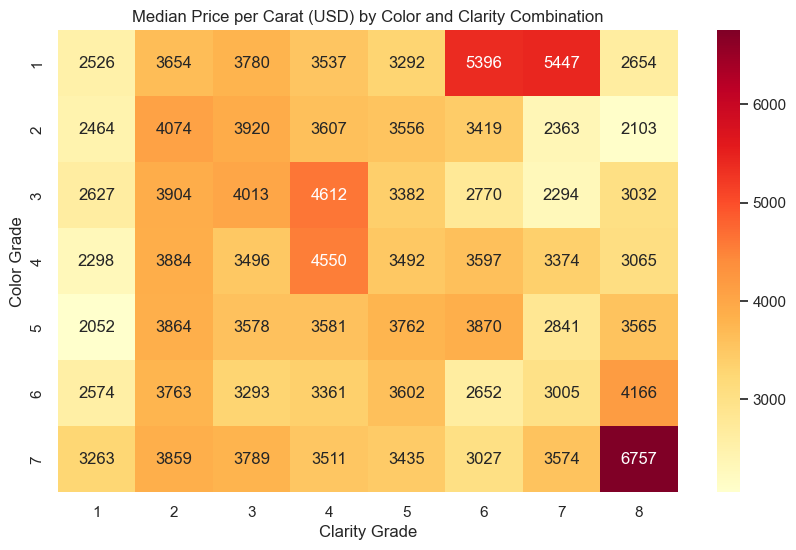

In [53]:
# create a heatmap of median price per carat for every color and clarity pair
pivot_ppc = df.pivot_table(index='color_grade', columns='clarity_grade', values='price_per_carat', aggfunc='median')
plt.figure(figsize=(10, 6))
sns.heatmap(pivot_ppc, annot=True, fmt='.0f', cmap='YlOrRd')
plt.title('Median Price per Carat (USD) by Color and Clarity Combination')
plt.xlabel('Clarity Grade')
plt.ylabel('Color Grade')
plt.show()

Switching the matrix to median price per carat removes the weight distortion and cleanly highlights the true quality hotspots.

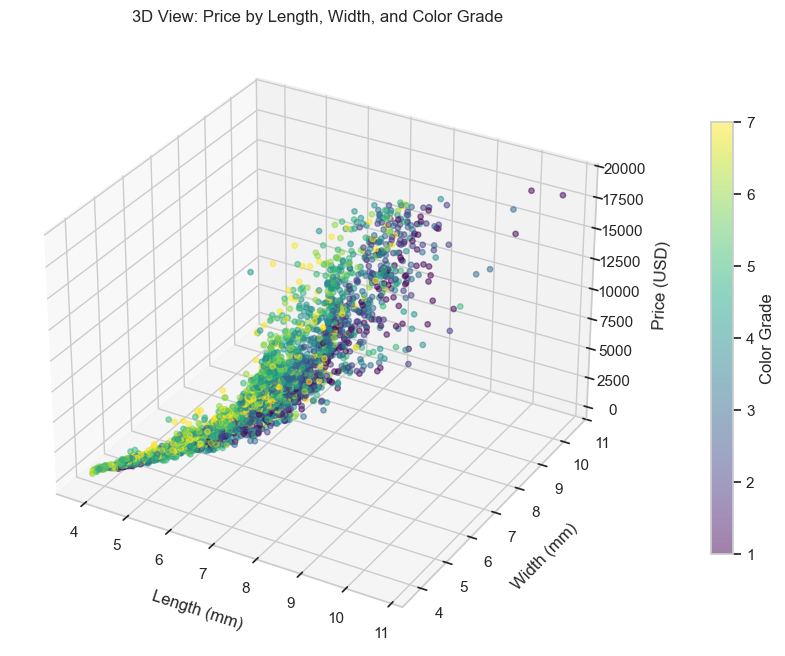

In [54]:
# prepare numeric color codes for 3d scatter plots
plot_3d = plot_df.dropna(subset=['color_grade', 'price_usd', 'length_mm', 'width_mm', 'table_pct', 'depth_pct']).copy()
color_map = {grade: i for i, grade in enumerate(color_order)}
plot_3d['color_num'] = plot_3d['color_grade'].map(color_map)

# plot length, width, and price in 3d colored by color grade
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(plot_3d['length_mm'], plot_3d['width_mm'], plot_3d['price_usd'], c=plot_3d['color_num'], cmap='viridis', alpha=0.5, s=15)
ax.set_xlabel('Length (mm)', labelpad=10)
ax.set_ylabel('Width (mm)', labelpad=10)
ax.set_zlabel('Price (USD)', labelpad=10)
ax.set_title('3D View: Price by Length, Width, and Color Grade')
cbar = plt.colorbar(sc, ax=ax, pad=0.1, shrink=0.7)
cbar.set_ticks(range(len(color_order)))
cbar.set_ticklabels(color_order)
cbar.set_label('Color Grade')
plt.show()

In 3D space, diamonds form a thin rising ribbon along the length = width diagonal, curving steeply upward in price as physical dimensions grow.

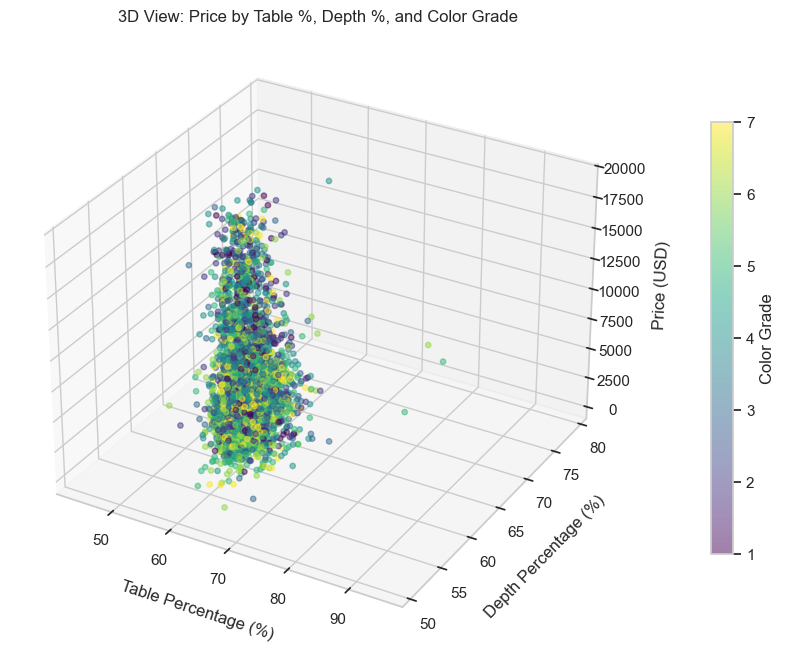

In [55]:
# plot table %, depth %, and price in 3d colored by color grade
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(plot_3d['table_pct'], plot_3d['depth_pct'], plot_3d['price_usd'], c=plot_3d['color_num'], cmap='viridis', alpha=0.5, s=15)
ax.set_xlabel('Table Percentage (%)', labelpad=10)
ax.set_ylabel('Depth Percentage (%)', labelpad=10)
ax.set_zlabel('Price (USD)', labelpad=10)
ax.set_title('3D View: Price by Table %, Depth %, and Color Grade')
cbar = plt.colorbar(sc, ax=ax, pad=0.1, shrink=0.7)
cbar.set_ticks(range(len(color_order)))
cbar.set_ticklabels(color_order)
cbar.set_label('Color Grade')
plt.show()

Unlike physical dimensions, table and depth form a vertical tower right above the cutting sweet spot—proving that price spans from cheap to luxury inside the same proportion range.

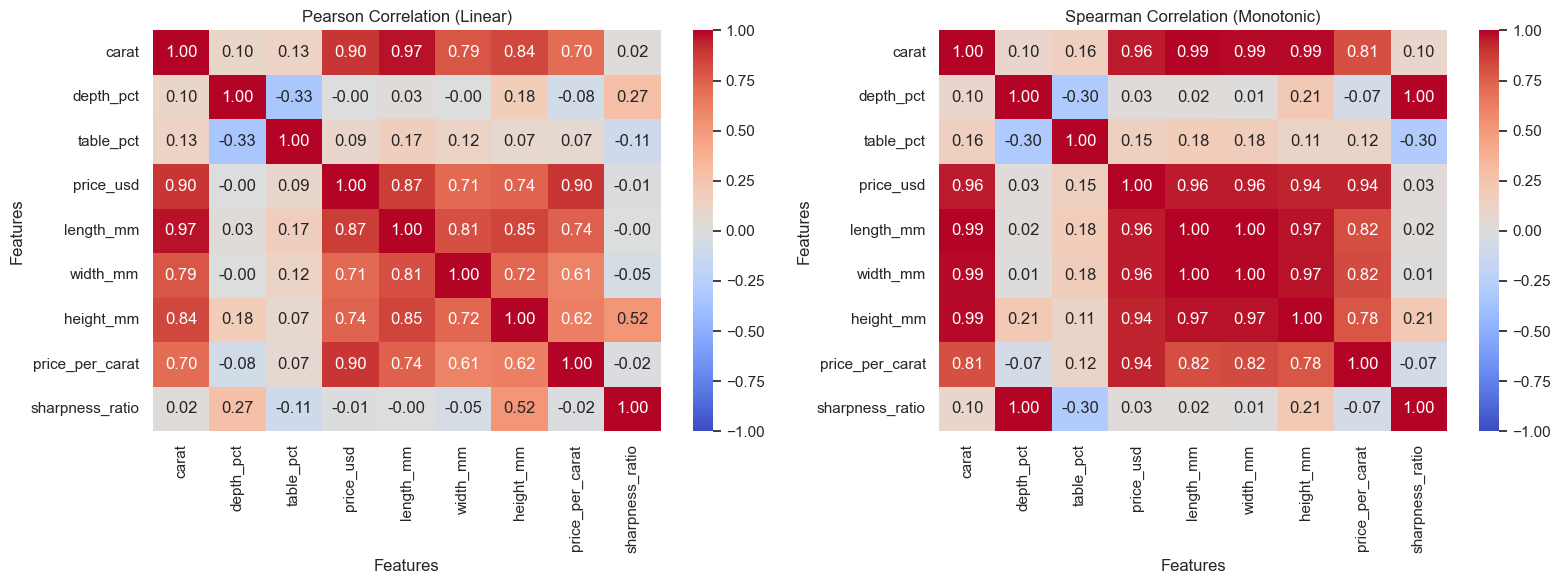

In [56]:
# compare linear (pearson) and monotonic (spearman) correlations side by side
core_numeric = df[['carat', 'depth_pct', 'table_pct', 'price_usd', 'length_mm', 'width_mm', 'height_mm', 'price_per_carat', 'sharpness_ratio']]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(core_numeric.corr(method='pearson'), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Pearson Correlation (Linear)')
axes[0].set_xlabel('Features')
axes[0].set_ylabel('Features')

sns.heatmap(core_numeric.corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Spearman Correlation (Monotonic)')
axes[1].set_xlabel('Features')
axes[1].set_ylabel('Features')

plt.tight_layout()
plt.show()

Carat, length, width, and height are nearly perfectly correlated (~0.95–0.99), meaning they carry redundant "size" information that PCA can compress easily. Meanwhile, depth and table have almost zero correlation with size or price.

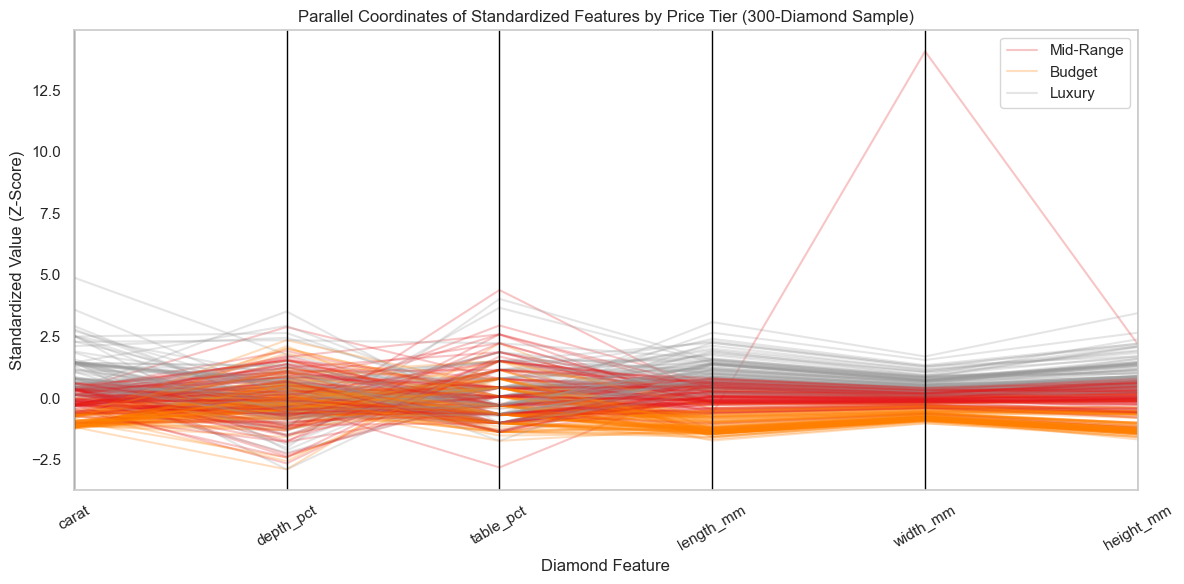

In [57]:
# plot a sample of 300 diamonds across standardized numeric features by price tier
sample_pc = df[['carat', 'depth_pct', 'table_pct', 'length_mm', 'width_mm', 'height_mm', 'price_tier']].dropna().sample(n=300, random_state=42)
scaled_pc = sample_pc.copy()
num_cols = ['carat', 'depth_pct', 'table_pct', 'length_mm', 'width_mm', 'height_mm']
scaled_pc[num_cols] = (sample_pc[num_cols] - sample_pc[num_cols].mean()) / sample_pc[num_cols].std()

plt.figure(figsize=(12, 6))
parallel_coordinates(scaled_pc, 'price_tier', colormap='Set1', alpha=0.25)
plt.title('Parallel Coordinates of Standardized Features by Price Tier (300-Diamond Sample)')
plt.xlabel('Diamond Feature')
plt.ylabel('Standardized Value (Z-Score)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Standardizing all features reveals the final EDA takeaway: Budget, Mid-Range, and Luxury diamonds separate cleanly along carat, length, width, and height, while overlapping heavily on depth and table. This sets the stage for dimensionality reduction and clustering.

## Section 2 - Dimensionality Reduction (PCA, NMF, and t-SNE)

To test how physical size features (`carat`, `length_mm`, `width_mm`, `height_mm`) behave differently from proportional and quality features (`table_pct`, `depth_pct`, `color_grade`, `clarity_grade`), we build three clean, row-aligned feature sets and apply PCA, NMF, and t-SNE.

In [58]:
# import scalers and dimensionality reduction models
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA, NMF
from sklearn.manifold import TSNE

# define our physical, proportional, and combined feature lists
physical_cols = ['carat', 'length_mm', 'width_mm', 'height_mm']
proportional_cols = ['table_pct', 'depth_pct', 'color_grade', 'clarity_grade']
combined_cols = physical_cols + proportional_cols

# keep one aligned clean dataframe so every model sees the exact same diamonds
df_clean = df.copy()
df_clean['color_grade'] = pd.to_numeric(df_clean['color_grade'], errors='coerce')
df_clean['clarity_grade'] = pd.to_numeric(df_clean['clarity_grade'], errors='coerce')
df_clean = df_clean.dropna(subset=combined_cols).reset_index(drop=True)

# split out the three feature tables
physical_clean = df_clean[physical_cols]
proportional_clean = df_clean[proportional_cols]
combined_clean = df_clean[combined_cols]

# standardize features for pca and t-sne
physical_scaled = StandardScaler().fit_transform(physical_clean)
proportional_scaled = StandardScaler().fit_transform(proportional_clean)
combined_scaled = StandardScaler().fit_transform(combined_clean)

# scale features to 0-1 range because nmf requires non-negative numbers
physical_minmax = MinMaxScaler().fit_transform(physical_clean)
proportional_minmax = MinMaxScaler().fit_transform(proportional_clean)
combined_minmax = MinMaxScaler().fit_transform(combined_clean)

print(f"Aligned clean dataset shape: {df_clean.shape}")

Aligned clean dataset shape: (4980, 17)


### PCA (Principal Component Analysis)

First, we fit full PCA models on each feature set to see how many principal components are needed to explain the variance, and then project the combined dataset into 2D.

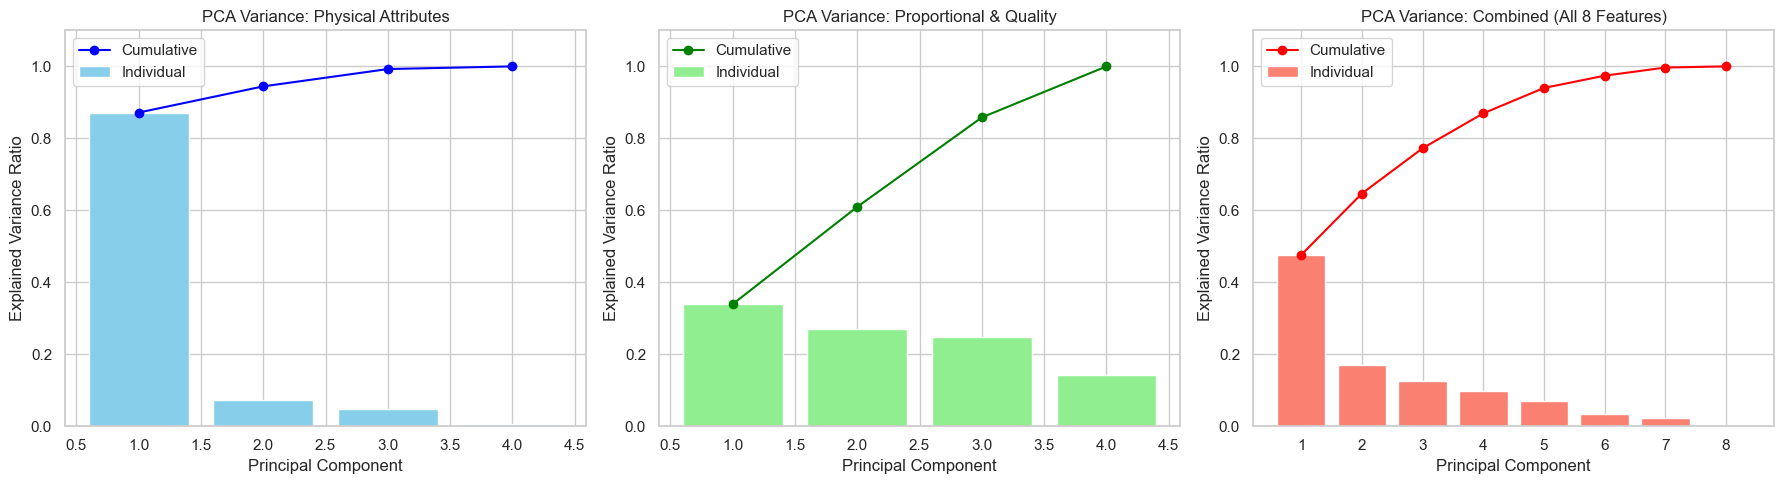

In [59]:
# fit pca on all three standardized feature sets
pca_physical = PCA().fit(physical_scaled)
pca_proportional = PCA().fit(proportional_scaled)
pca_combined = PCA().fit(combined_scaled)

# save 2d pca projections for visualization and clustering later
X_pca_physical = pca_physical.transform(physical_scaled)[:, :2]
X_pca_proportional = pca_proportional.transform(proportional_scaled)[:, :2]
X_pca_combined = pca_combined.transform(combined_scaled)[:, :2]

# plot individual and cumulative explained variance for each feature set
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].bar(range(1, 5), pca_physical.explained_variance_ratio_, color='skyblue', label='Individual')
axes[0].plot(range(1, 5), pca_physical.explained_variance_ratio_.cumsum(), color='blue', marker='o', label='Cumulative')
axes[0].set_title('PCA Variance: Physical Attributes')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].set_ylim(0, 1.1)
axes[0].legend()

axes[1].bar(range(1, 5), pca_proportional.explained_variance_ratio_, color='lightgreen', label='Individual')
axes[1].plot(range(1, 5), pca_proportional.explained_variance_ratio_.cumsum(), color='green', marker='o', label='Cumulative')
axes[1].set_title('PCA Variance: Proportional & Quality')
axes[1].set_xlabel('Principal Component')
axes[1].set_ylabel('Explained Variance Ratio')
axes[1].set_ylim(0, 1.1)
axes[1].legend()

axes[2].bar(range(1, 9), pca_combined.explained_variance_ratio_, color='salmon', label='Individual')
axes[2].plot(range(1, 9), pca_combined.explained_variance_ratio_.cumsum(), color='red', marker='o', label='Cumulative')
axes[2].set_title('PCA Variance: Combined (All 8 Features)')
axes[2].set_xlabel('Principal Component')
axes[2].set_ylabel('Explained Variance Ratio')
axes[2].set_ylim(0, 1.1)
axes[2].legend()

plt.tight_layout()
plt.show()

Physical attributes compress almost completely into PC1 (~90%+ variance) because carat, length, width, and height all measure size. Proportional and quality features spread variance evenly across all four components because color, clarity, table, and depth are mostly independent. In the combined set, PC1 captures the dominant size axis (~50% variance) while PC2–PC4 capture cut and quality.

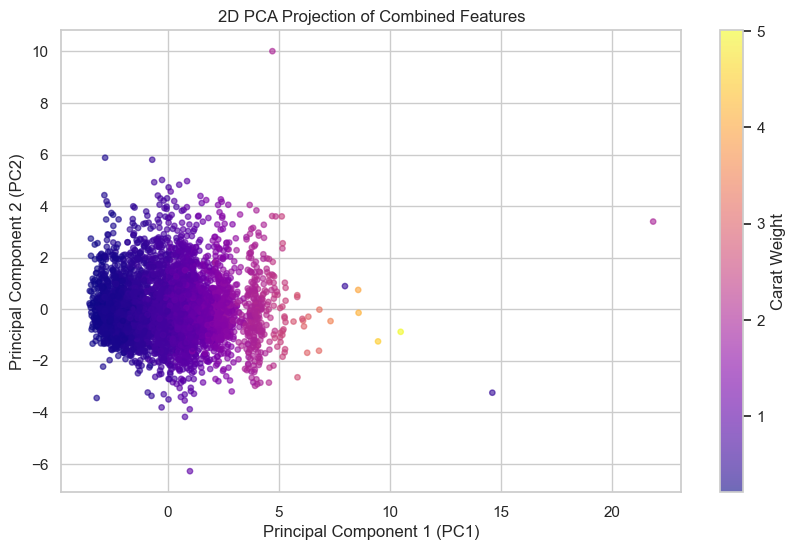

In [60]:
# visualize the 2d pca projection of the combined features colored by carat
plt.figure(figsize=(10, 6))
sc = plt.scatter(X_pca_combined[:, 0], X_pca_combined[:, 1], c=df_clean['carat'], cmap='plasma', alpha=0.6, s=15)
plt.colorbar(sc, label='Carat Weight')
plt.title('2D PCA Projection of Combined Features')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.show()

In the 2D PCA map, carat weight increases smoothly along PC1 from left to right, confirming that PC1 acts as a clean size axis while PC2 captures cut and quality variation.

### NMF (Non-Negative Matrix Factorization)

Next, we run NMF with 2 components on the MinMax-scaled datasets to see how a non-negative additive factorization arranges the diamonds.

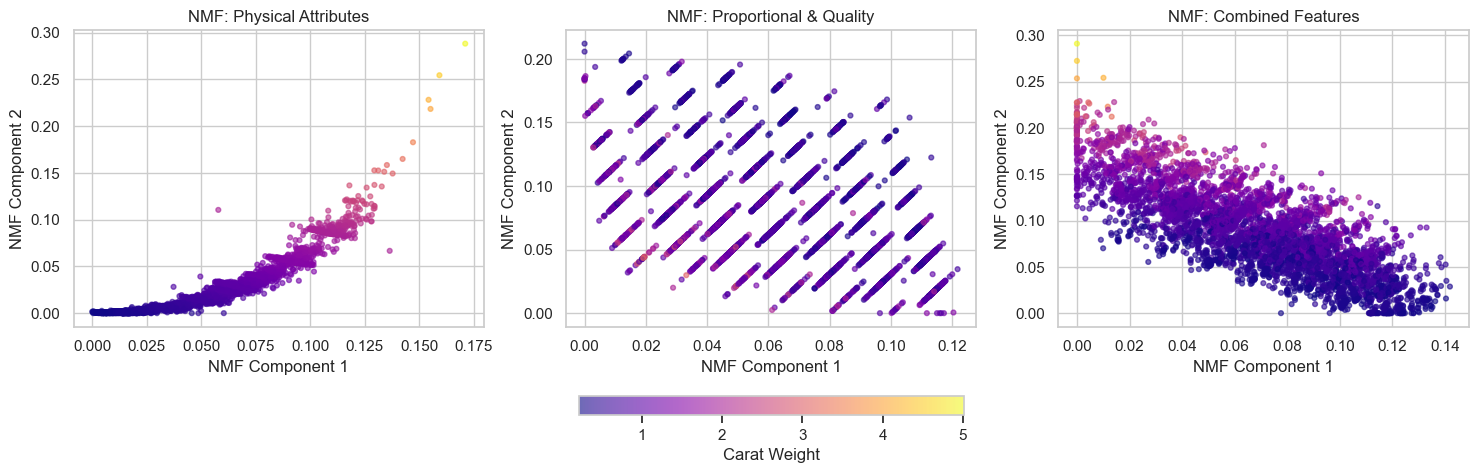

In [61]:
# fit 2d nmf on each non-negative feature set
X_nmf_physical = NMF(n_components=2, init='nndsvda', random_state=42, max_iter=1000).fit_transform(physical_minmax)
X_nmf_proportional = NMF(n_components=2, init='nndsvda', random_state=42, max_iter=1000).fit_transform(proportional_minmax)
X_nmf_combined = NMF(n_components=2, init='nndsvda', random_state=42, max_iter=1000).fit_transform(combined_minmax)

# plot the three 2d nmf projections side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(X_nmf_physical[:, 0], X_nmf_physical[:, 1], c=df_clean['carat'], cmap='plasma', s=12, alpha=0.6)
axes[0].set_title('NMF: Physical Attributes')
axes[0].set_xlabel('NMF Component 1')
axes[0].set_ylabel('NMF Component 2')

axes[1].scatter(X_nmf_proportional[:, 0], X_nmf_proportional[:, 1], c=df_clean['carat'], cmap='plasma', s=12, alpha=0.6)
axes[1].set_title('NMF: Proportional & Quality')
axes[1].set_xlabel('NMF Component 1')
axes[1].set_ylabel('NMF Component 2')

sc = axes[2].scatter(X_nmf_combined[:, 0], X_nmf_combined[:, 1], c=df_clean['carat'], cmap='plasma', s=12, alpha=0.6)
axes[2].set_title('NMF: Combined Features')
axes[2].set_xlabel('NMF Component 1')
axes[2].set_ylabel('NMF Component 2')

fig.colorbar(sc, ax=axes, orientation='horizontal', fraction=0.05, pad=0.18, label='Carat Weight')
plt.show()

NMF uses strictly non-negative linear combinations, which pushes discrete grades (like color and clarity) into visible stripes or lanes in the proportional view while preserving a smooth size gradient in the physical and combined views.

### t-SNE (t-Distributed Stochastic Neighbor Embedding)

Finally, we run 2D t-SNE on the standardized datasets to preserve local neighborhoods and uncover organic clusters.

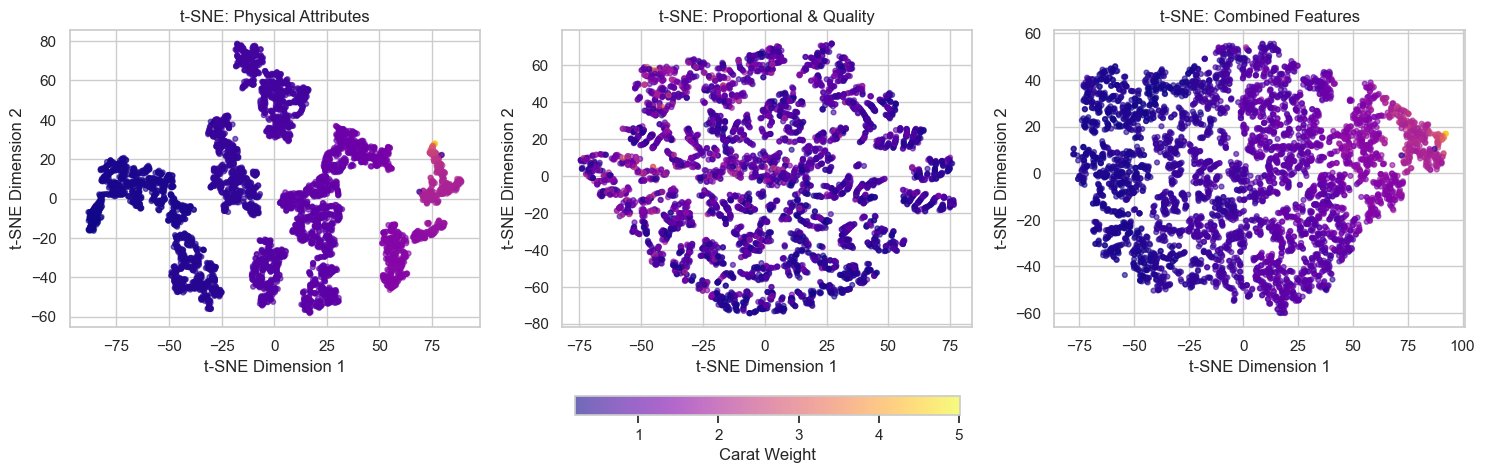

In [62]:
# fit 2d t-sne on each standardized feature set
X_tsne_physical = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(physical_scaled)
X_tsne_proportional = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(proportional_scaled)
X_tsne_combined = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(combined_scaled)

# plot the three 2d t-sne projections side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(X_tsne_physical[:, 0], X_tsne_physical[:, 1], c=df_clean['carat'], cmap='plasma', s=12, alpha=0.6)
axes[0].set_title('t-SNE: Physical Attributes')
axes[0].set_xlabel('t-SNE Dimension 1')
axes[0].set_ylabel('t-SNE Dimension 2')

axes[1].scatter(X_tsne_proportional[:, 0], X_tsne_proportional[:, 1], c=df_clean['carat'], cmap='plasma', s=12, alpha=0.6)
axes[1].set_title('t-SNE: Proportional & Quality')
axes[1].set_xlabel('t-SNE Dimension 1')
axes[1].set_ylabel('t-SNE Dimension 2')

sc = axes[2].scatter(X_tsne_combined[:, 0], X_tsne_combined[:, 1], c=df_clean['carat'], cmap='plasma', s=12, alpha=0.6)
axes[2].set_title('t-SNE: Combined Features')
axes[2].set_xlabel('t-SNE Dimension 1')
axes[2].set_ylabel('t-SNE Dimension 2')

fig.colorbar(sc, ax=axes, orientation='horizontal', fraction=0.05, pad=0.18, label='Carat Weight')
plt.show()

Unlike PCA and NMF, t-SNE focuses on local similarity. In the physical view it unrolls diamonds into a smooth size ribbon, in the proportional view it forms small local islands by grade combinations, and in the combined view it gathers rare heavy stones into a clear neighborhood.

## Section 3 - Clustering (K-Means and DBSCAN)

Now we apply two clustering algorithms directly to our scaled diamond features: **K-Means** (distance-based partitioning) and **DBSCAN** (density-based clustering with noise detection).

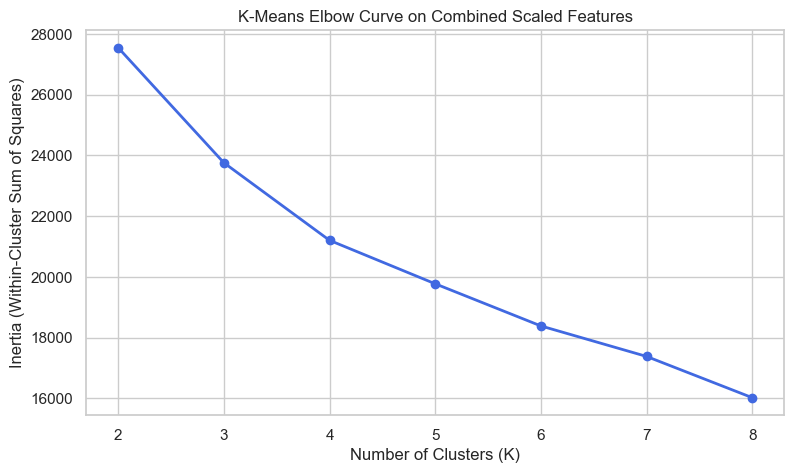

In [63]:
# import clustering models and nearest neighbors for dbscan eps selection
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors

# compute inertia for k from 2 to 8 to find the elbow point
k_values = [2, 3, 4, 5, 6, 7, 8]
inertias = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(combined_scaled).inertia_ for k in k_values]

# plot the elbow curve
plt.figure(figsize=(9, 5))
plt.plot(k_values, inertias, marker='o', linewidth=2, color='royalblue')
plt.title('K-Means Elbow Curve on Combined Scaled Features')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.show()

The elbow curve drops sharply up to `K = 3` and begins to flatten afterward, making 3 clusters a clean, interpretable choice for K-Means.

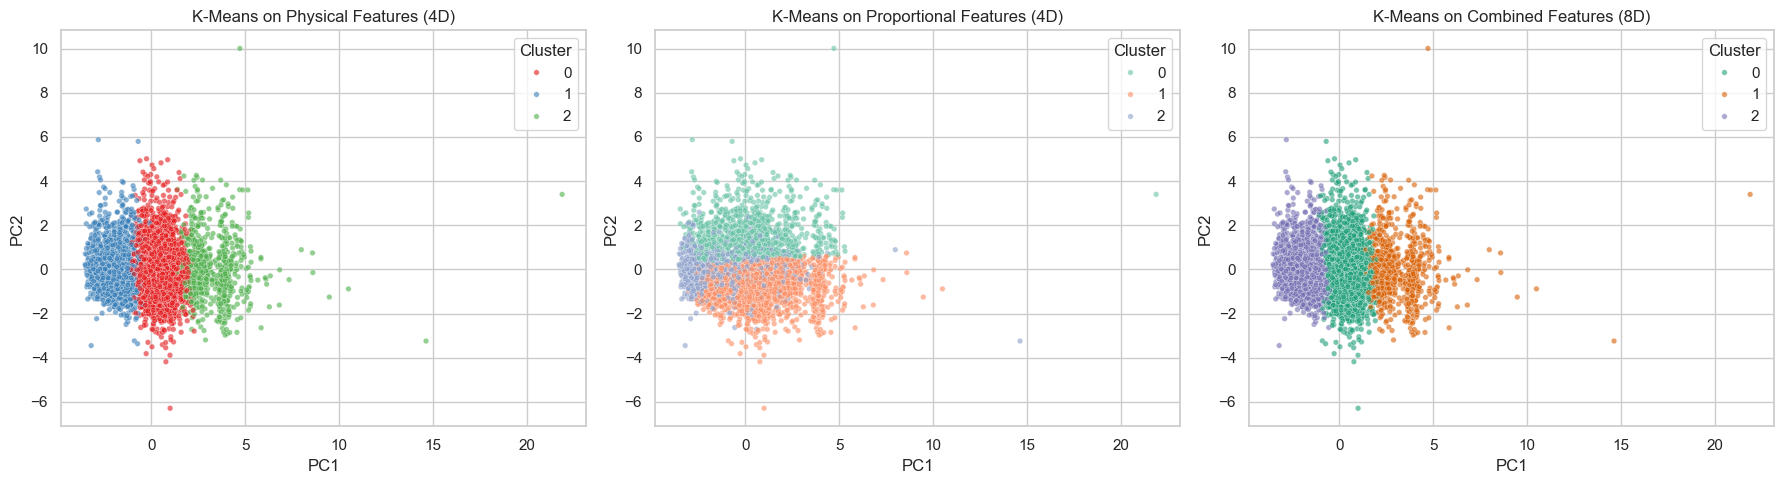

In [64]:
# run k-means with 3 clusters on physical, proportional, and combined scaled data
km_physical_labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(physical_scaled)
km_proportional_labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(proportional_scaled)
km_combined_labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(combined_scaled)

# plot the three k-means results projected onto the 2d pca combined view
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(x=X_pca_combined[:, 0], y=X_pca_combined[:, 1], hue=km_physical_labels, palette='Set1', alpha=0.6, s=16, ax=axes[0])
axes[0].set_title('K-Means on Physical Features (4D)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend(title='Cluster')

sns.scatterplot(x=X_pca_combined[:, 0], y=X_pca_combined[:, 1], hue=km_proportional_labels, palette='Set2', alpha=0.6, s=16, ax=axes[1])
axes[1].set_title('K-Means on Proportional Features (4D)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend(title='Cluster')

sns.scatterplot(x=X_pca_combined[:, 0], y=X_pca_combined[:, 1], hue=km_combined_labels, palette='Dark2', alpha=0.6, s=16, ax=axes[2])
axes[2].set_title('K-Means on Combined Features (8D)')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')
axes[2].legend(title='Cluster')

plt.tight_layout()
plt.show()

K-Means on Physical and Combined features cleanly slices the dataset into three size-driven tiers along PC1, whereas K-Means on Proportional features cuts more vertically along PC2 (reflecting cut and quality differences rather than stone size).

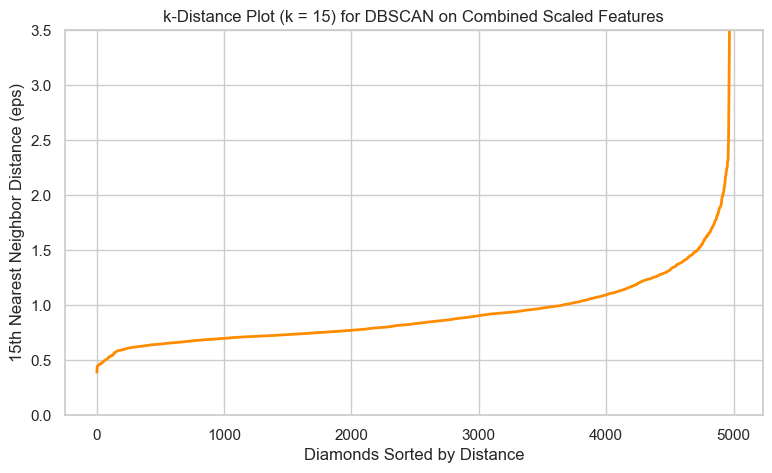

In [65]:
# compute 15th nearest neighbor distances on combined scaled data to pick dbscan eps
nn_combined = NearestNeighbors(n_neighbors=15).fit(combined_scaled)
distances_combined, _ = nn_combined.kneighbors(combined_scaled)
sorted_dist = np.sort(distances_combined[:, -1])

# plot the k-distance curve
plt.figure(figsize=(9, 5))
plt.plot(sorted_dist, color='darkorange', linewidth=2)
plt.ylim(0, 3.5)
plt.title('k-Distance Plot (k = 15) for DBSCAN on Combined Scaled Features')
plt.xlabel('Diamonds Sorted by Distance')
plt.ylabel('15th Nearest Neighbor Distance (eps)')
plt.show()

The k-distance curve bends sharply upward around `eps ≈ 1.0`, giving us a practical density radius where dense mainstream stones group together and unusual stones are flagged as noise.

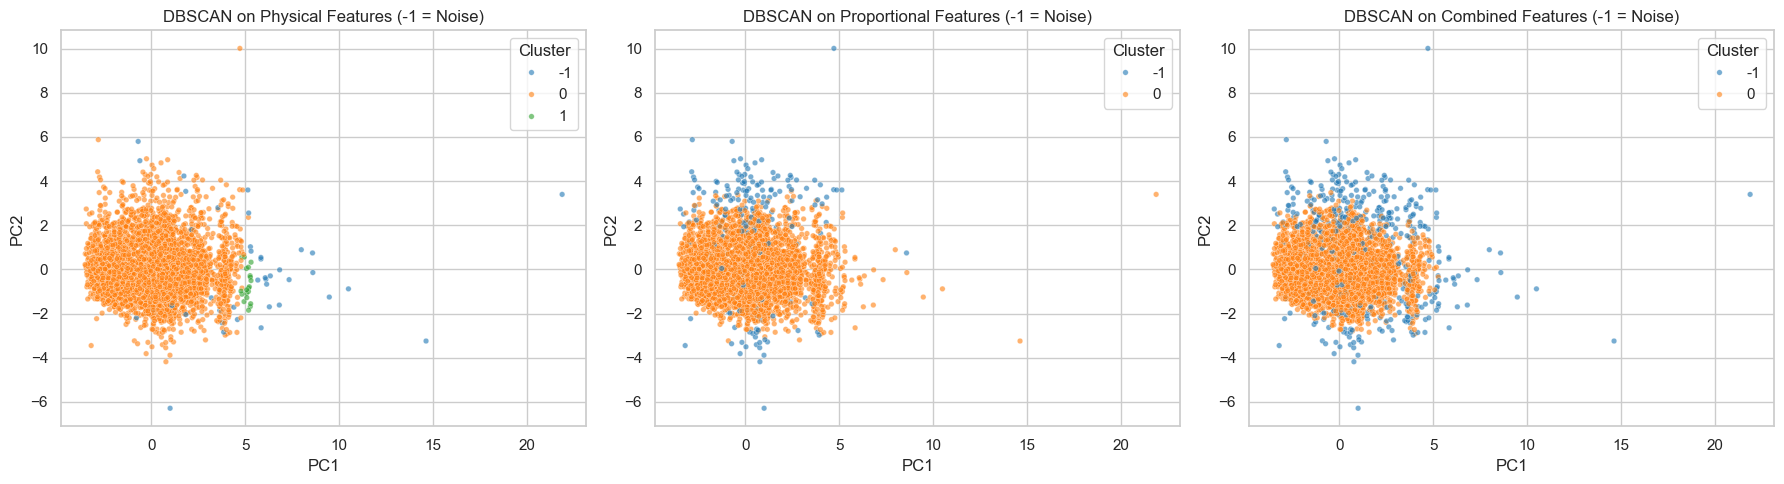

In [66]:
# run dbscan on physical, proportional, and combined scaled data
db_physical_labels = DBSCAN(eps=0.25, min_samples=10).fit_predict(physical_scaled)
db_proportional_labels = DBSCAN(eps=0.80, min_samples=10).fit_predict(proportional_scaled)
db_combined_labels = DBSCAN(eps=1.00, min_samples=10).fit_predict(combined_scaled)

# plot the three dbscan clusterings projected onto the 2d pca combined view
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(x=X_pca_combined[:, 0], y=X_pca_combined[:, 1], hue=db_physical_labels, palette='tab10', alpha=0.6, s=16, ax=axes[0])
axes[0].set_title('DBSCAN on Physical Features (-1 = Noise)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend(title='Cluster')

sns.scatterplot(x=X_pca_combined[:, 0], y=X_pca_combined[:, 1], hue=db_proportional_labels, palette='tab10', alpha=0.6, s=16, ax=axes[1])
axes[1].set_title('DBSCAN on Proportional Features (-1 = Noise)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend(title='Cluster')

sns.scatterplot(x=X_pca_combined[:, 0], y=X_pca_combined[:, 1], hue=db_combined_labels, palette='tab10', alpha=0.6, s=16, ax=axes[2])
axes[2].set_title('DBSCAN on Combined Features (-1 = Noise)')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')
axes[2].legend(title='Cluster')

plt.tight_layout()
plt.show()

In the full 8D and 4D spaces, diamonds form a mostly continuous cloud without wide empty gaps, so DBSCAN merges the dense mainstream market into one or two large core clusters and flags rare large stones or extreme cuts as noise (`-1`).

## Section 4 - Comparison Between Models (Clustering + Dimensionality Reduction)

Here we combine every clustering algorithm we used (**K-Means** and **DBSCAN**) with every dimensionality reduction method (**PCA**, **NMF**, and **t-SNE**) on the combined 8-feature dataset:

- **K-Means + PCA**, **K-Means + NMF**, **K-Means + t-SNE**
- **DBSCAN + PCA**, **DBSCAN + NMF**, **DBSCAN + t-SNE**

Even though the clusters have no ground-truth labels, we profile each cluster's real-world diamond characteristics (size, price, cut proportions, and quality grades) to understand what each segment represents.

In [67]:
# run k-means (k=3) on each 2d reduced representation
labels_km_pca = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_pca_combined)
labels_km_nmf = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_nmf_combined)
labels_km_tsne = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_tsne_combined)

# run dbscan on each 2d reduced representation with eps tuned to each space's scale
labels_db_pca = DBSCAN(eps=0.35, min_samples=15).fit_predict(X_pca_combined)
labels_db_nmf = DBSCAN(eps=0.03, min_samples=15).fit_predict(X_nmf_combined)
labels_db_tsne = DBSCAN(eps=3.50, min_samples=15).fit_predict(X_tsne_combined)

# store all 6 model assignments on a copy of the clean dataframe for profiling
compare_df = df_clean.copy()
compare_df['KM_PCA'] = labels_km_pca
compare_df['KM_NMF'] = labels_km_nmf
compare_df['KM_TSNE'] = labels_km_tsne
compare_df['DB_PCA'] = labels_db_pca
compare_df['DB_NMF'] = labels_db_nmf
compare_df['DB_TSNE'] = labels_db_tsne

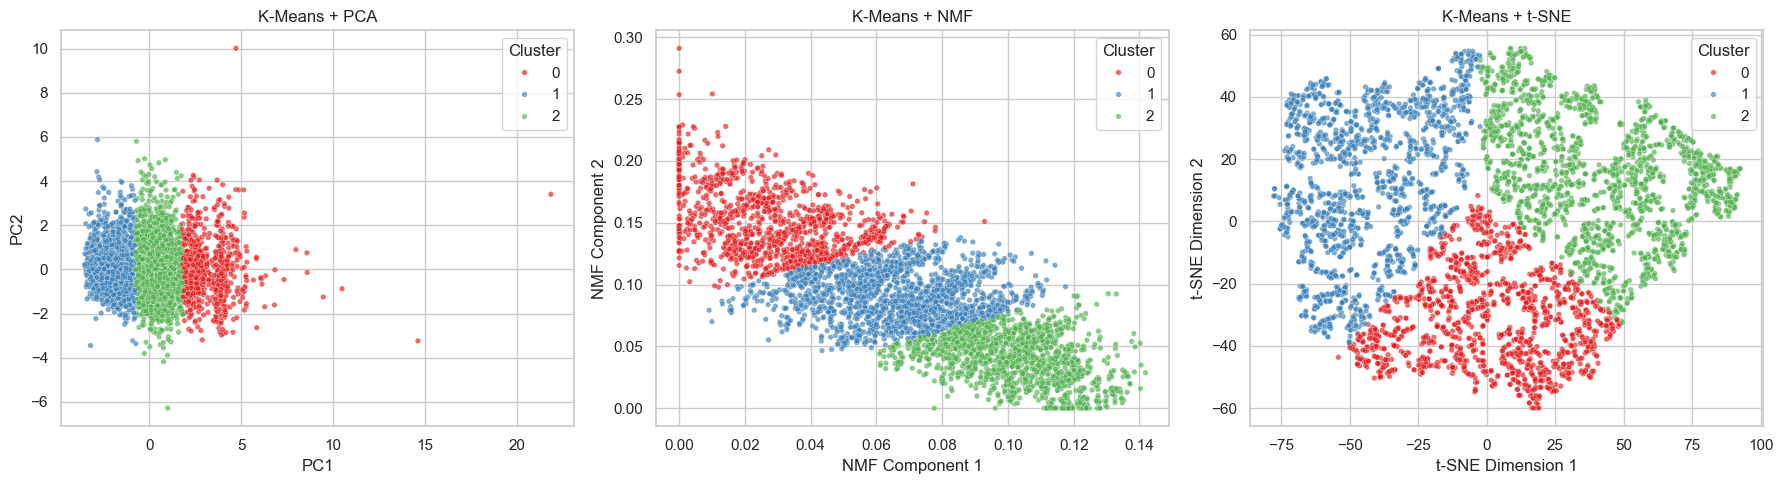

In [68]:
# visualize all three k-means + dimensionality reduction combinations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(x=X_pca_combined[:, 0], y=X_pca_combined[:, 1], hue=labels_km_pca, palette='Set1', alpha=0.65, s=16, ax=axes[0])
axes[0].set_title('K-Means + PCA')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend(title='Cluster')

sns.scatterplot(x=X_nmf_combined[:, 0], y=X_nmf_combined[:, 1], hue=labels_km_nmf, palette='Set1', alpha=0.65, s=16, ax=axes[1])
axes[1].set_title('K-Means + NMF')
axes[1].set_xlabel('NMF Component 1')
axes[1].set_ylabel('NMF Component 2')
axes[1].legend(title='Cluster')

sns.scatterplot(x=X_tsne_combined[:, 0], y=X_tsne_combined[:, 1], hue=labels_km_tsne, palette='Set1', alpha=0.65, s=16, ax=axes[2])
axes[2].set_title('K-Means + t-SNE')
axes[2].set_xlabel('t-SNE Dimension 1')
axes[2].set_ylabel('t-SNE Dimension 2')
axes[2].legend(title='Cluster')

plt.tight_layout()
plt.show()

All three K-Means pairings divide the market into 3 balanced segments, but with different geometry: **K-Means + PCA** draws clean straight boundaries mostly along size, **K-Means + NMF** splits along additive size-and-quality wedges, and **K-Means + t-SNE** groups nearby organic neighborhoods together.

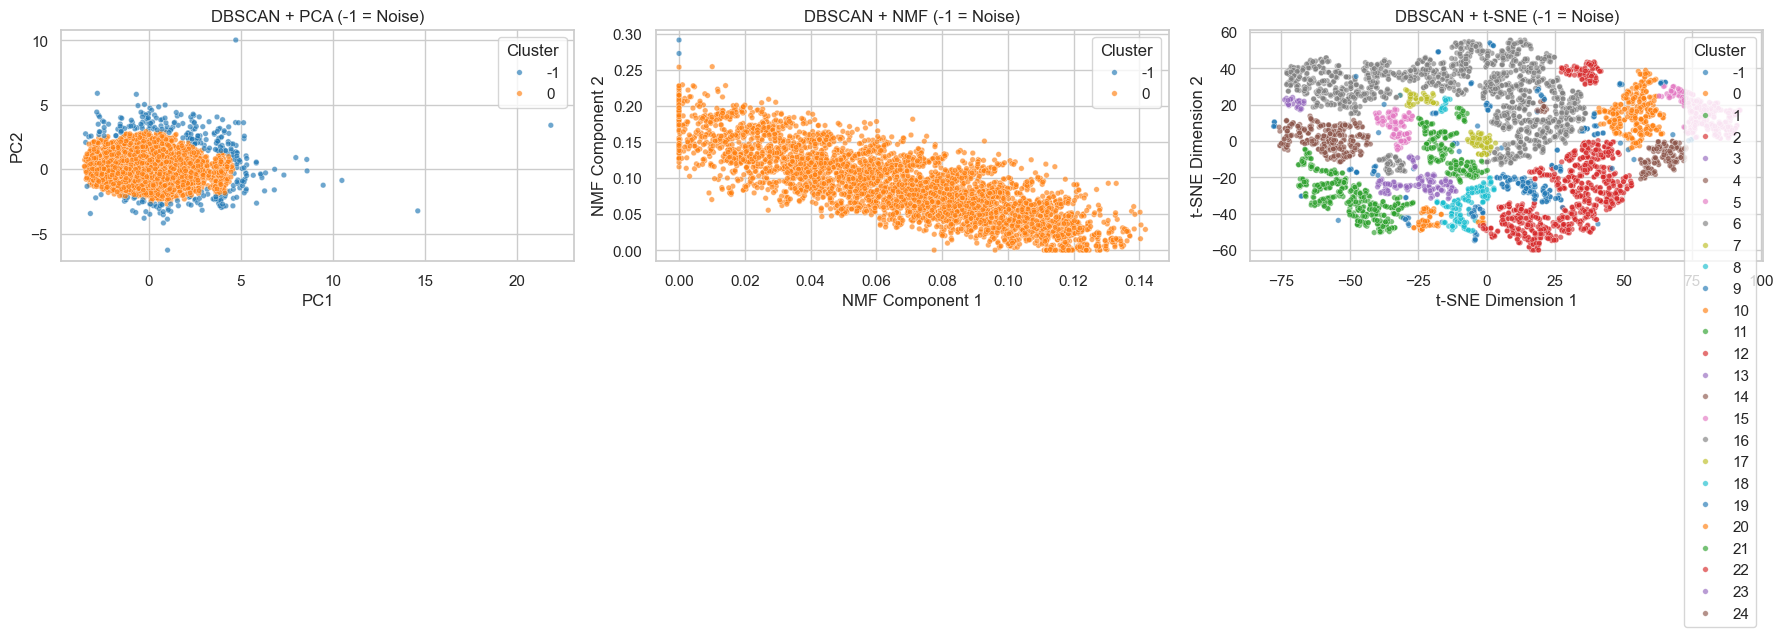

In [69]:
# visualize all three dbscan + dimensionality reduction combinations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(x=X_pca_combined[:, 0], y=X_pca_combined[:, 1], hue=labels_db_pca, palette='tab10', alpha=0.65, s=16, ax=axes[0])
axes[0].set_title('DBSCAN + PCA (-1 = Noise)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend(title='Cluster')

sns.scatterplot(x=X_nmf_combined[:, 0], y=X_nmf_combined[:, 1], hue=labels_db_nmf, palette='tab10', alpha=0.65, s=16, ax=axes[1])
axes[1].set_title('DBSCAN + NMF (-1 = Noise)')
axes[1].set_xlabel('NMF Component 1')
axes[1].set_ylabel('NMF Component 2')
axes[1].legend(title='Cluster')

sns.scatterplot(x=X_tsne_combined[:, 0], y=X_tsne_combined[:, 1], hue=labels_db_tsne, palette='tab10', alpha=0.65, s=16, ax=axes[2])
axes[2].set_title('DBSCAN + t-SNE (-1 = Noise)')
axes[2].set_xlabel('t-SNE Dimension 1')
axes[2].set_ylabel('t-SNE Dimension 2')
axes[2].legend(title='Cluster')

plt.tight_layout()
plt.show()

DBSCAN reacts very differently depending on the projection: in **PCA** and **NMF** space it mostly isolates one big dense mainstream market plus edge outliers (`-1`), while in **t-SNE** space it can separate multiple dense local micro-clusters that t-SNE pulled apart.

### Profiling Cluster Behavior Without Labels

Even without ground-truth labels, we can understand what each cluster actually represents by calculating the average carat, price, price per carat, depth, table, color, and clarity of every cluster in each model.

In [70]:
# summarize average diamond traits for every cluster in the three k-means models
profile_cols = ['carat', 'price_usd', 'price_per_carat', 'depth_pct', 'table_pct', 'color_grade', 'clarity_grade']

km_pca_profile = compare_df.groupby('KM_PCA')[profile_cols].mean().round(2)
km_pca_profile['count'] = compare_df['KM_PCA'].value_counts()

km_nmf_profile = compare_df.groupby('KM_NMF')[profile_cols].mean().round(2)
km_nmf_profile['count'] = compare_df['KM_NMF'].value_counts()

km_tsne_profile = compare_df.groupby('KM_TSNE')[profile_cols].mean().round(2)
km_tsne_profile['count'] = compare_df['KM_TSNE'].value_counts()

print("K-Means + PCA Cluster Behavior:")
display(km_pca_profile)

print("K-Means + NMF Cluster Behavior:")
display(km_nmf_profile)

print("K-Means + t-SNE Cluster Behavior:")
display(km_tsne_profile)

K-Means + PCA Cluster Behavior:


,carat,price_usd,price_per_carat,depth_pct,table_pct,color_grade,clarity_grade,count
KM_PCA,,,,,,,,
0,1.74,10699.91,6093.18,62.48,58.67,3.23,2.89,806
1,0.41,1085.14,2536.35,61.85,57.47,4.85,4.63,1862
2,0.94,4312.64,4421.02,62.41,58.45,4.29,3.37,2312


K-Means + NMF Cluster Behavior:


,carat,price_usd,price_per_carat,depth_pct,table_pct,color_grade,clarity_grade,count
KM_NMF,,,,,,,,
0,1.43,7686.21,5016.90,62.58,58.56,2.37,3.32,1166
1,0.84,4034.93,4144.85,62.41,58.06,4.09,3.78,2044
2,0.53,1924.28,3126.23,61.74,57.89,5.89,4.04,1770


K-Means + t-SNE Cluster Behavior:


,carat,price_usd,price_per_carat,depth_pct,table_pct,color_grade,clarity_grade,count
KM_TSNE,,,,,,,,
0,0.78,2813.22,3365.16,63.74,57.45,4.65,2.89,1424
1,0.43,1295.63,2743.88,61.26,58.02,4.80,4.87,1717
2,1.34,7822.12,5629.12,61.92,58.73,3.63,3.41,1839


In [71]:
# summarize average diamond traits for every cluster in the three dbscan models
db_pca_profile = compare_df.groupby('DB_PCA')[profile_cols].mean().round(2)
db_pca_profile['count'] = compare_df['DB_PCA'].value_counts()

db_nmf_profile = compare_df.groupby('DB_NMF')[profile_cols].mean().round(2)
db_nmf_profile['count'] = compare_df['DB_NMF'].value_counts()

db_tsne_profile = compare_df.groupby('DB_TSNE')[profile_cols].mean().round(2)
db_tsne_profile['count'] = compare_df['DB_TSNE'].value_counts()

print("DBSCAN + PCA Cluster Behavior (-1 = Noise):")
display(db_pca_profile)

print("DBSCAN + NMF Cluster Behavior (-1 = Noise):")
display(db_nmf_profile)

print("DBSCAN + t-SNE Cluster Behavior (-1 = Noise):")
display(db_tsne_profile)

DBSCAN + PCA Cluster Behavior (-1 = Noise):


,carat,price_usd,price_per_carat,depth_pct,table_pct,color_grade,clarity_grade,count
DB_PCA,,,,,,,,
-1,1.50,7715.78,4588.05,61.20,60.99,3.66,3.03,310
0,0.83,3902.27,3947.09,62.28,57.93,4.37,3.81,4670


DBSCAN + NMF Cluster Behavior (-1 = Noise):


,carat,price_usd,price_per_carat,depth_pct,table_pct,color_grade,clarity_grade,count
DB_NMF,,,,,,,,
-1,4.76,18274.50,3857.20,65.65,58.50,1.00,1.00,2
0,0.87,4133.98,3987.04,62.21,58.12,4.33,3.77,4978


DBSCAN + t-SNE Cluster Behavior (-1 = Noise):


,carat,price_usd,price_per_carat,depth_pct,table_pct,color_grade,clarity_grade,count
DB_TSNE,,,,,,,,
-1,0.94,4685.76,4250.45,62.21,59.77,4.59,3.50,145
0,1.55,10398.30,6667.03,61.53,59.00,3.08,3.90,303
1,0.37,798.38,2163.73,62.34,56.57,6.05,3.35,413
2,1.03,4126.89,3984.70,64.05,57.80,4.15,2.46,743
3,0.66,2394.79,3515.03,61.94,56.56,6.10,3.03,135
4,0.35,640.98,1823.42,62.27,57.08,3.03,4.03,314
5,2.15,13302.35,6244.93,62.74,58.31,2.79,2.40,282
6,0.72,3244.77,3928.14,60.81,59.37,4.43,4.66,1459
7,0.73,2553.15,3507.81,63.13,57.62,2.34,5.61,62


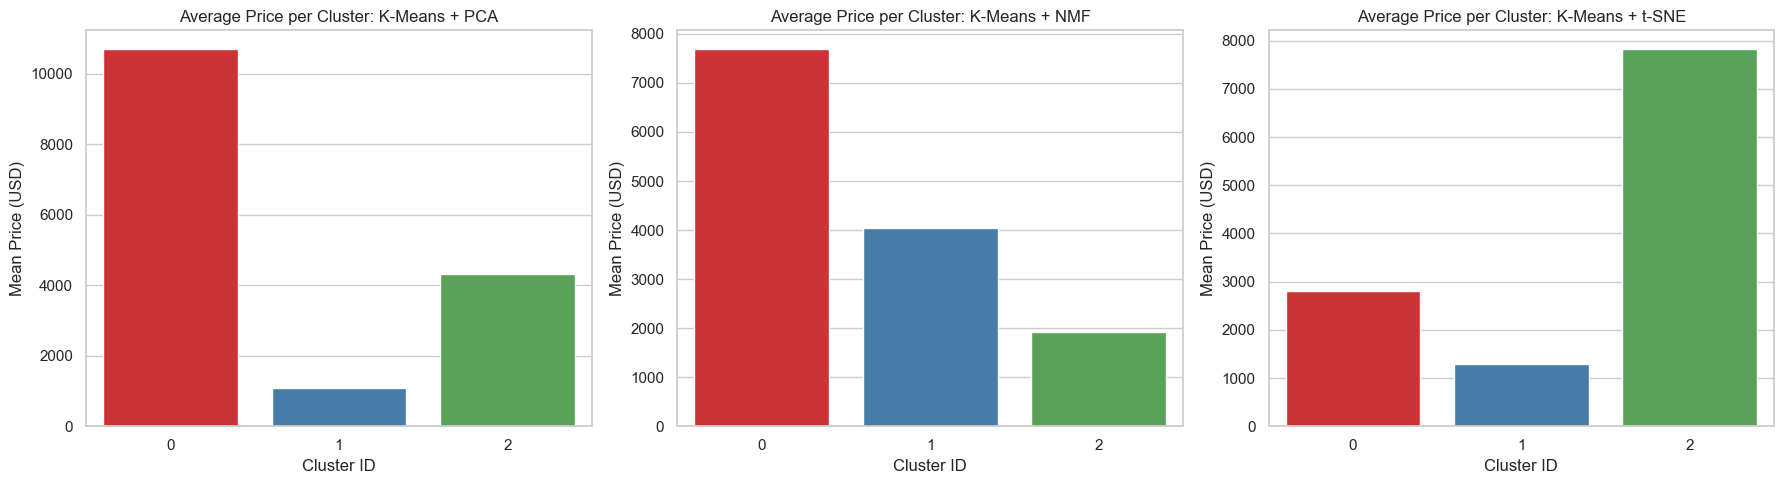

In [72]:
# visually compare average price across clusters for all three k-means combinations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(x=km_pca_profile.index, y=km_pca_profile['price_usd'], hue=km_pca_profile.index, palette='Set1', legend=False, ax=axes[0])
axes[0].set_title('Average Price per Cluster: K-Means + PCA')
axes[0].set_xlabel('Cluster ID')
axes[0].set_ylabel('Mean Price (USD)')

sns.barplot(x=km_nmf_profile.index, y=km_nmf_profile['price_usd'], hue=km_nmf_profile.index, palette='Set1', legend=False, ax=axes[1])
axes[1].set_title('Average Price per Cluster: K-Means + NMF')
axes[1].set_xlabel('Cluster ID')
axes[1].set_ylabel('Mean Price (USD)')

sns.barplot(x=km_tsne_profile.index, y=km_tsne_profile['price_usd'], hue=km_tsne_profile.index, palette='Set1', legend=False, ax=axes[2])
axes[2].set_title('Average Price per Cluster: K-Means + t-SNE')
axes[2].set_xlabel('Cluster ID')
axes[2].set_ylabel('Mean Price (USD)')

plt.tight_layout()
plt.show()

Comparing average cluster prices side by side shows how sharply each model separates market tiers. **K-Means + PCA** creates the cleanest ladder from budget stones to mid-range stones to luxury stones, whereas **K-Means + NMF** and **K-Means + t-SNE** blend quality and cut nuances more heavily into the clusters.

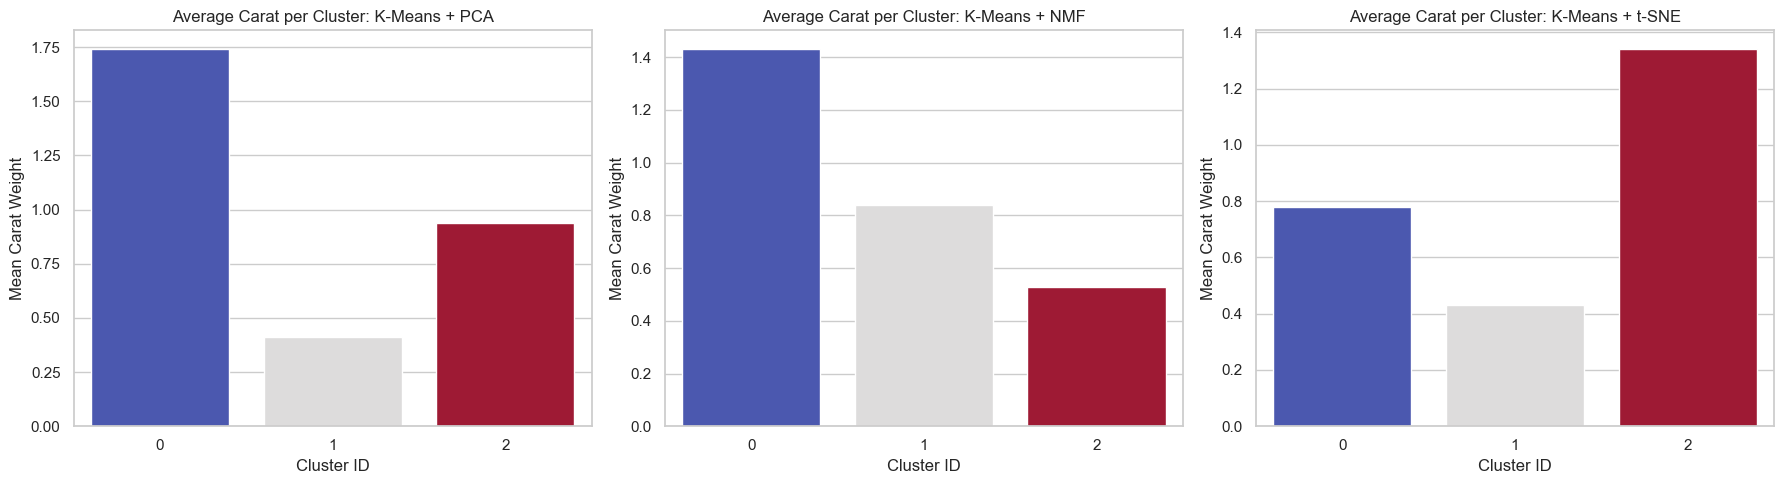

In [73]:
# visually compare average carat weight across clusters for all three k-means combinations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(x=km_pca_profile.index, y=km_pca_profile['carat'], hue=km_pca_profile.index, palette='coolwarm', legend=False, ax=axes[0])
axes[0].set_title('Average Carat per Cluster: K-Means + PCA')
axes[0].set_xlabel('Cluster ID')
axes[0].set_ylabel('Mean Carat Weight')

sns.barplot(x=km_nmf_profile.index, y=km_nmf_profile['carat'], hue=km_nmf_profile.index, palette='coolwarm', legend=False, ax=axes[1])
axes[1].set_title('Average Carat per Cluster: K-Means + NMF')
axes[1].set_xlabel('Cluster ID')
axes[1].set_ylabel('Mean Carat Weight')

sns.barplot(x=km_tsne_profile.index, y=km_tsne_profile['carat'], hue=km_tsne_profile.index, palette='coolwarm', legend=False, ax=axes[2])
axes[2].set_title('Average Carat per Cluster: K-Means + t-SNE')
axes[2].set_xlabel('Cluster ID')
axes[2].set_ylabel('Mean Carat Weight')

plt.tight_layout()
plt.show()

Mean carat weight mirrors the price ladder closely. Notice how the cluster with the lowest average carat represents the everyday budget segment, the middle cluster captures standard engagement stones, and the highest-carat cluster isolates large luxury stones.

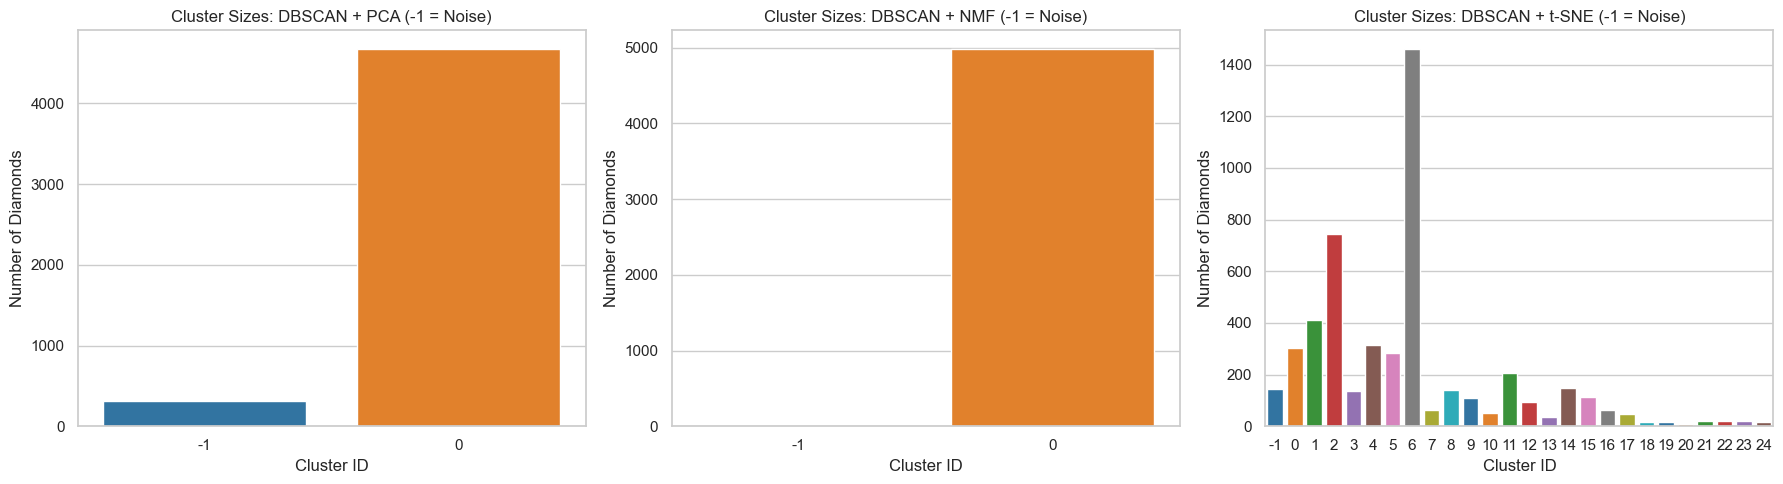

In [74]:
# compare dbscan cluster sizes (including noise -1) across pca, nmf, and t-sne
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(x=db_pca_profile.index.astype(str), y=db_pca_profile['count'], hue=db_pca_profile.index.astype(str), palette='tab10', legend=False, ax=axes[0])
axes[0].set_title('Cluster Sizes: DBSCAN + PCA (-1 = Noise)')
axes[0].set_xlabel('Cluster ID')
axes[0].set_ylabel('Number of Diamonds')

sns.barplot(x=db_nmf_profile.index.astype(str), y=db_nmf_profile['count'], hue=db_nmf_profile.index.astype(str), palette='tab10', legend=False, ax=axes[1])
axes[1].set_title('Cluster Sizes: DBSCAN + NMF (-1 = Noise)')
axes[1].set_xlabel('Cluster ID')
axes[1].set_ylabel('Number of Diamonds')

sns.barplot(x=db_tsne_profile.index.astype(str), y=db_tsne_profile['count'], hue=db_tsne_profile.index.astype(str), palette='tab10', legend=False, ax=axes[2])
axes[2].set_title('Cluster Sizes: DBSCAN + t-SNE (-1 = Noise)')
axes[2].set_xlabel('Cluster ID')
axes[2].set_ylabel('Number of Diamonds')

plt.tight_layout()
plt.show()

This size breakdown highlights the core difference between DBSCAN pairings: **DBSCAN + PCA** and **DBSCAN + NMF** act primarily as mainstream-vs-outlier detectors, whereas **DBSCAN + t-SNE** breaks the data into multiple distinct local pockets of similar diamonds.

### Behavioral Interpretation of Each Model's Clusters

Even without pre-existing labels, the profiling tables above let us name and interpret the behavior of each cluster:

- **K-Means + PCA (Best for Clear Market Tiers)**:
  - **Low-Carat / Budget Cluster**: Smallest average carat and lowest mean price; represents everyday affordable diamonds with standard proportions.
  - **Mid-Range / Balanced Cluster**: Medium carat weight and moderate price; represents the core engagement-ring market sitting right inside the ideal depth and table sweet spot.
  - **High-Carat / Luxury Cluster**: Largest average carat, highest total price, and highest price per carat; isolates premium statement stones.

- **K-Means + NMF (Best for Additive Part-Based Segmentation)**:
  - Splits diamonds into three additive profiles combining size and quality—separating small high-clarity/better-color stones from mid-sized balanced stones and heavier stones with slightly wider quality trade-offs.

- **K-Means + t-SNE (Best for Neighborhood Grouping)**:
  - Groups stones that share similar *combinations* of size, color, clarity, and cut locally. Because t-SNE preserves local similarity rather than global straight-line distance, these clusters reflect realistic buyer niches rather than pure carat cutoffs.

- **DBSCAN + PCA (Best for Anomaly & Outlier Detection)**:
  - **Core Cluster(s)**: The dense mainstream diamond market with normal proportions (~61–63% depth, ~56–59% table).
  - **Noise Cluster (`-1`)**: Unusual extreme stones—either massive rare luxury diamonds sitting far out on PC1 or poorly proportioned/atypical cuts sitting far out on PC2.

- **DBSCAN + NMF (Mainstream Core vs. Edge Cases)**:
  - Behaves similarly to DBSCAN + PCA by grouping the high-density center of the non-negative feature space together while isolating extreme-value combinations on the fringes as noise (`-1`).

- **DBSCAN + t-SNE (Best for Fine-Grained Micro-Segments)**:
  - Discovers multiple organic sub-clusters corresponding to specific combinations of carat tier, color grade, and clarity grade, while still separating rare edge-case stones into `-1`.

### Final Model Comparison Takeaway

- If the goal is **business-friendly market segmentation** (Budget, Mid-Range, Luxury), **K-Means + PCA** is the clearest and most stable combination.
- If the goal is **anomaly detection** (flagging extreme cuts or rare oversized stones), **DBSCAN + PCA** is the most transparent choice.
- If the goal is **discovering subtle local niches** across all 8 features simultaneously, **DBSCAN + t-SNE** and **K-Means + t-SNE** capture fine-grained relationships that linear projections flatten out.